<center><h1>Shelar_Kartik_HW4</h1></center>
<br>
<br>

Name: Kartik Shelar
<br>
Github Username: kartikshelar
<br>
USC ID: 4217403571

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
from pathlib import PurePosixPath
from zipfile import ZipFile
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.special import expit

from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score,
    cross_validate
)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

Get the AReM Data Set

In [2]:
zip_path = "AReM.zip"

columns = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]


def read_instance(zip_file, file_name):
    raw_text = zip_file.read(file_name).decode("utf-8-sig")
    rows = []

    for line in raw_text.splitlines():
        line = line.strip().rstrip(",").strip()

        if not line or line.startswith("#"):
            continue

        values = re.split(r"[,\s]+", line)
        rows.append(values)

    df = pd.DataFrame(rows, columns=columns)
    return df.apply(pd.to_numeric, errors="raise")


instances = []

with ZipFile(zip_path, "r") as zip_file:
    csv_files = sorted(
        file_name
        for file_name in zip_file.namelist()
        if file_name.lower().endswith(".csv")
    )

    for file_name in csv_files:
        instances.append({
            "activity": PurePosixPath(file_name).parent.name,
            "dataset": PurePosixPath(file_name).stem,
            "file_name": file_name,
            "data": read_instance(zip_file, file_name)
        })

print("Number of instances:", len(instances))

Number of instances: 88


In [3]:
data_summary = pd.DataFrame([
    {
        "activity": item["activity"],
        "dataset": item["dataset"],
        "observations": len(item["data"])
    }
    for item in instances
])

data_summary.groupby("activity").agg(
    instances=("dataset", "count"),
    minimum_rows=("observations", "min"),
    maximum_rows=("observations", "max")
)

,instances,minimum_rows,maximum_rows
activity,,,
bending1,7,480,480
bending2,6,480,480
cycling,15,480,480
lying,15,480,480
sitting,15,479,480
standing,15,480,480
walking,15,480,480


All 88 instances load correctly. The loader handles space-separated rows and trailing commas. `sitting/dataset8.csv` has 479 rows instead of 480, which does not affect the summary-statistic features.

### (b) Splitting Data

In [4]:
train_instances = []
test_instances = []

for item in instances:
    activity = item["activity"]
    dataset_number = int(item["dataset"].replace("dataset", ""))

    if activity in ["bending1", "bending2"]:
        is_test = dataset_number in [1, 2]
    else:
        is_test = dataset_number in [1, 2, 3]

    if is_test:
        test_instances.append(item)
    else:
        train_instances.append(item)

print("Training instances:", len(train_instances))
print("Test instances:", len(test_instances))

Training instances: 69
Test instances: 19


In [5]:
split_summary = pd.DataFrame({
    "train": pd.Series(
        [item["activity"] for item in train_instances]
    ).value_counts(),
    "test": pd.Series(
        [item["activity"] for item in test_instances]
    ).value_counts()
}).sort_index()

split_summary.loc["Total"] = split_summary.sum()
split_summary

,train,test
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3
Total,69,19


### (c) Feature Extraction

In [6]:
sensor_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

statistics = [
    "min",
    "max",
    "mean",
    "median",
    "std",
    "1st_quart",
    "3rd_quart"
]


def extract_features(instance_list):
    feature_rows = []

    for item in instance_list:
        row = {
            "activity": item["activity"],
            "dataset": item["dataset"],
            "file_name": item["file_name"]
        }

        for series_number, column in enumerate(sensor_columns, start=1):
            series = item["data"][column]

            row[f"min{series_number}"] = series.min()
            row[f"max{series_number}"] = series.max()
            row[f"mean{series_number}"] = series.mean()
            row[f"median{series_number}"] = series.median()
            row[f"std{series_number}"] = series.std()
            row[f"1st_quart{series_number}"] = series.quantile(0.25)
            row[f"3rd_quart{series_number}"] = series.quantile(0.75)

        feature_rows.append(row)

    return pd.DataFrame(feature_rows)


feature_columns = [
    f"{stat}{series_number}"
    for series_number in range(1, 7)
    for stat in statistics
]

train_feature_df = extract_features(train_instances)
test_feature_df = extract_features(test_instances)

print("Training feature shape:", train_feature_df[feature_columns].shape)
print("Test feature shape:", test_feature_df[feature_columns].shape)
print(
    "Missing values:",
    train_feature_df[feature_columns].isna().sum().sum()
    + test_feature_df[feature_columns].isna().sum().sum()
)

Training feature shape: (69, 42)
Test feature shape: (19, 42)
Missing values: 0


In [7]:
selected_feature_types = [
    "mean",
    "std",
    "3rd_quart"
]

selected_features = [
    f"{stat}{series_number}"
    for series_number in range(1, 7)
    for stat in selected_feature_types
]

print("Number of selected features:", len(selected_features))

Number of selected features: 18


Seven time-domain features (min, max, mean, median, standard deviation, first quartile, third quartile) were extracted from each of the six time series, giving 42 features per instance. As in Homework 3, the mean, standard deviation, and third quartile were selected as the three most important feature types (18 features across the six series).

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [8]:
binary_train_df = train_feature_df.copy()

binary_train_df["class"] = np.where(
    binary_train_df["activity"].isin(["bending1", "bending2"]),
    "Bending",
    "Other"
)

binary_train_df["class"].value_counts()

class
Other      60
Bending     9
Name: count, dtype: int64

In [9]:
series_numbers = [1, 2, 6]

plot_features = [
    f"{stat}{series_number}"
    for series_number in series_numbers
    for stat in selected_feature_types
]

plot_features

['mean1',
 'std1',
 '3rd_quart1',
 'mean2',
 'std2',
 '3rd_quart2',
 'mean6',
 'std6',
 '3rd_quart6']

In [10]:
rename_map = {}

for series_number in series_numbers:
    rename_map[f"mean{series_number}"] = f"TS{series_number} Mean"
    rename_map[f"std{series_number}"] = f"TS{series_number} Std"
    rename_map[f"3rd_quart{series_number}"] = (
        f"TS{series_number} Third Quartile"
    )

plot_df = binary_train_df[plot_features + ["class"]].rename(
    columns=rename_map
)

plot_variables = [rename_map[feature] for feature in plot_features]

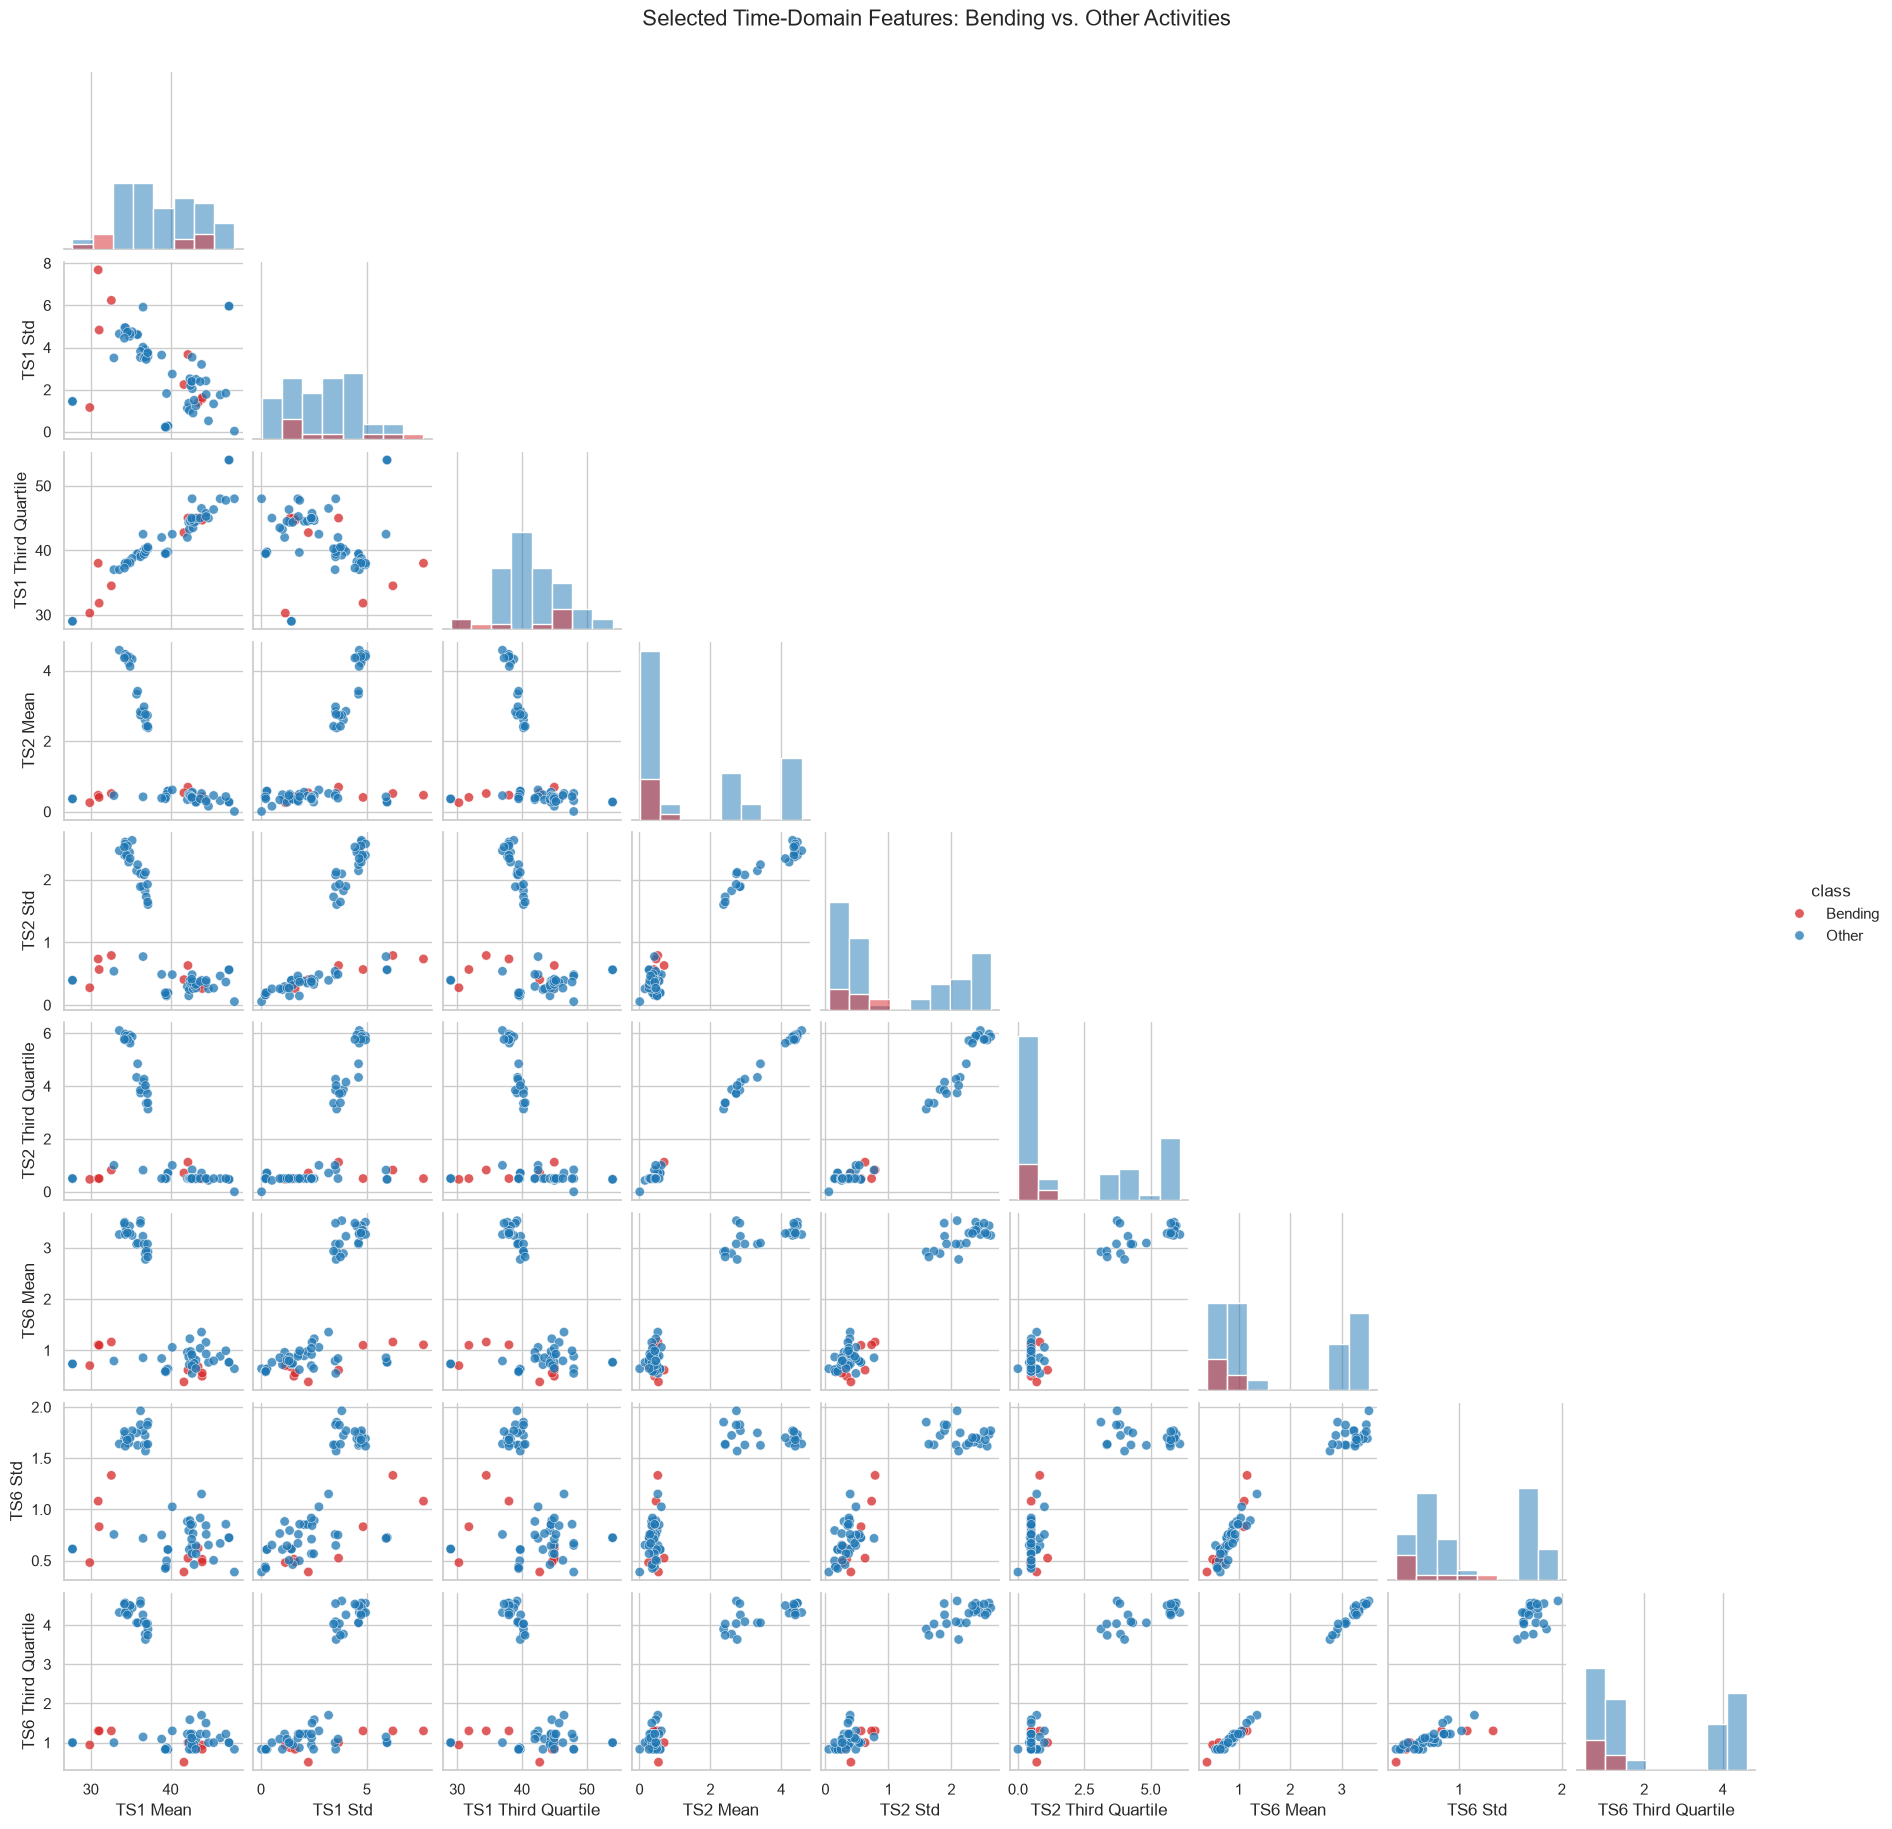

In [11]:
sns.set_theme(style="whitegrid")

grid = sns.pairplot(
    data=plot_df,
    vars=plot_variables,
    hue="class",
    hue_order=["Bending", "Other"],
    palette={
        "Bending": "#d62728",
        "Other": "#1f77b4"
    },
    diag_kind="hist",
    corner=True,
    height=2,
    plot_kws={
        "alpha": 0.75,
        "s": 45,
        "edgecolor": "white",
        "linewidth": 0.4
    }
)

grid.fig.suptitle(
    "Selected Time-Domain Features: Bending vs. Other Activities",
    y=1.02,
    fontsize=16
)

plt.show()

Time series 2 and 6 mainly separate the dynamic activities (cycling and walking, which have much higher values) from the static ones, but bending overlaps with the other static activities on these series. Time series 1 does the most to set bending apart: several bending instances have a low mean with a high standard deviation. No pair of features separates the two classes perfectly, and the classes are imbalanced (9 bending vs. 60 other).

#### ii. Split Plots

In [12]:
def extract_segmented_features(
    instance_list,
    number_of_segments,
    feature_types
):
    feature_rows = []

    for item in instance_list:
        row = {
            "activity": item["activity"],
            "dataset": item["dataset"],
            "file_name": item["file_name"]
        }

        data = item["data"]

        segment_indices = np.array_split(
            np.arange(len(data)),
            number_of_segments
        )

        for series_number, column in enumerate(
            sensor_columns,
            start=1
        ):
            for segment_number, indices in enumerate(
                segment_indices,
                start=1
            ):
                series = data.iloc[indices][column]

                statistic_values = {
                    "min": series.min(),
                    "max": series.max(),
                    "mean": series.mean(),
                    "median": series.median(),
                    "std": series.std(),
                    "1st_quart": series.quantile(0.25),
                    "3rd_quart": series.quantile(0.75)
                }

                for statistic in feature_types:
                    feature_name = (
                        f"{statistic}{series_number}"
                        f"_part{segment_number}"
                    )

                    row[feature_name] = statistic_values[statistic]

        feature_rows.append(row)

    return pd.DataFrame(feature_rows)


def prepare_segmented_data(
    instance_list,
    number_of_segments
):
    segmented_df = extract_segmented_features(
        instance_list,
        number_of_segments=number_of_segments,
        feature_types=statistics
    )

    feature_names = [
        column
        for column in segmented_df.columns
        if column not in [
            "activity",
            "dataset",
            "file_name"
        ]
    ]

    X = segmented_df[feature_names]
    y = segmented_df["activity"]

    return X, y, feature_names


def to_binary(activity_labels):
    return activity_labels.isin(["bending1", "bending2"]).astype(int)

In [13]:
segmented_train_df = extract_segmented_features(
    instance_list=train_instances,
    number_of_segments=2,
    feature_types=selected_feature_types
)

segmented_train_df["class"] = np.where(
    segmented_train_df["activity"].isin(["bending1", "bending2"]),
    "Bending",
    "Other"
)

print("Shape:", segmented_train_df.shape)

Shape: (69, 40)


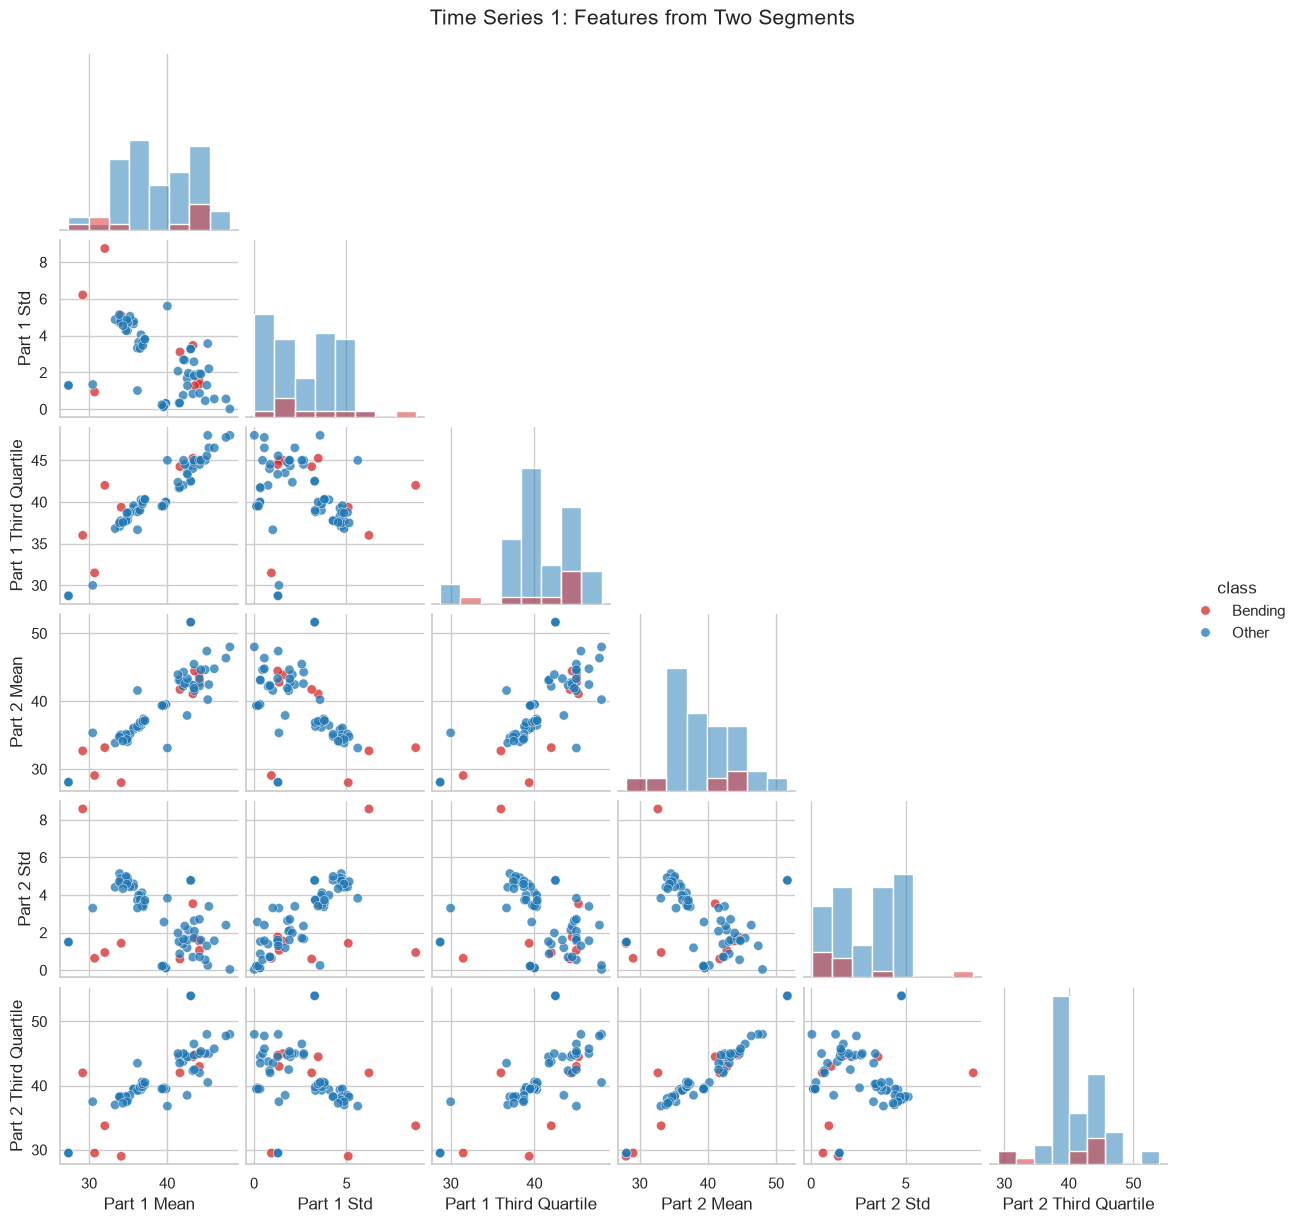

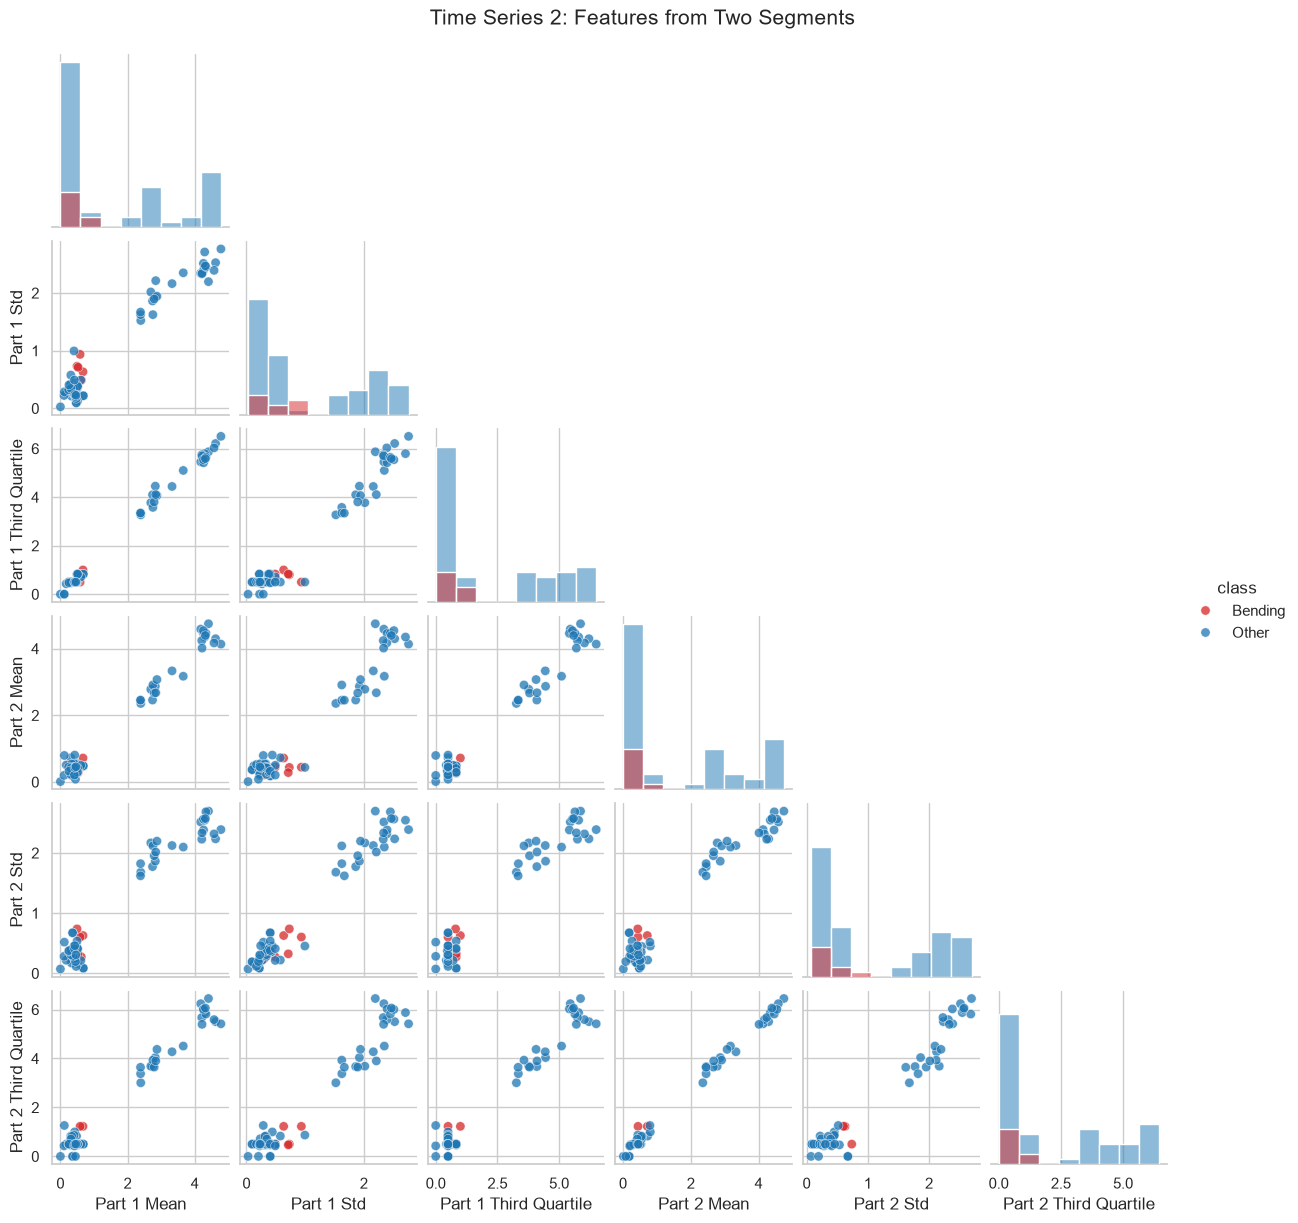

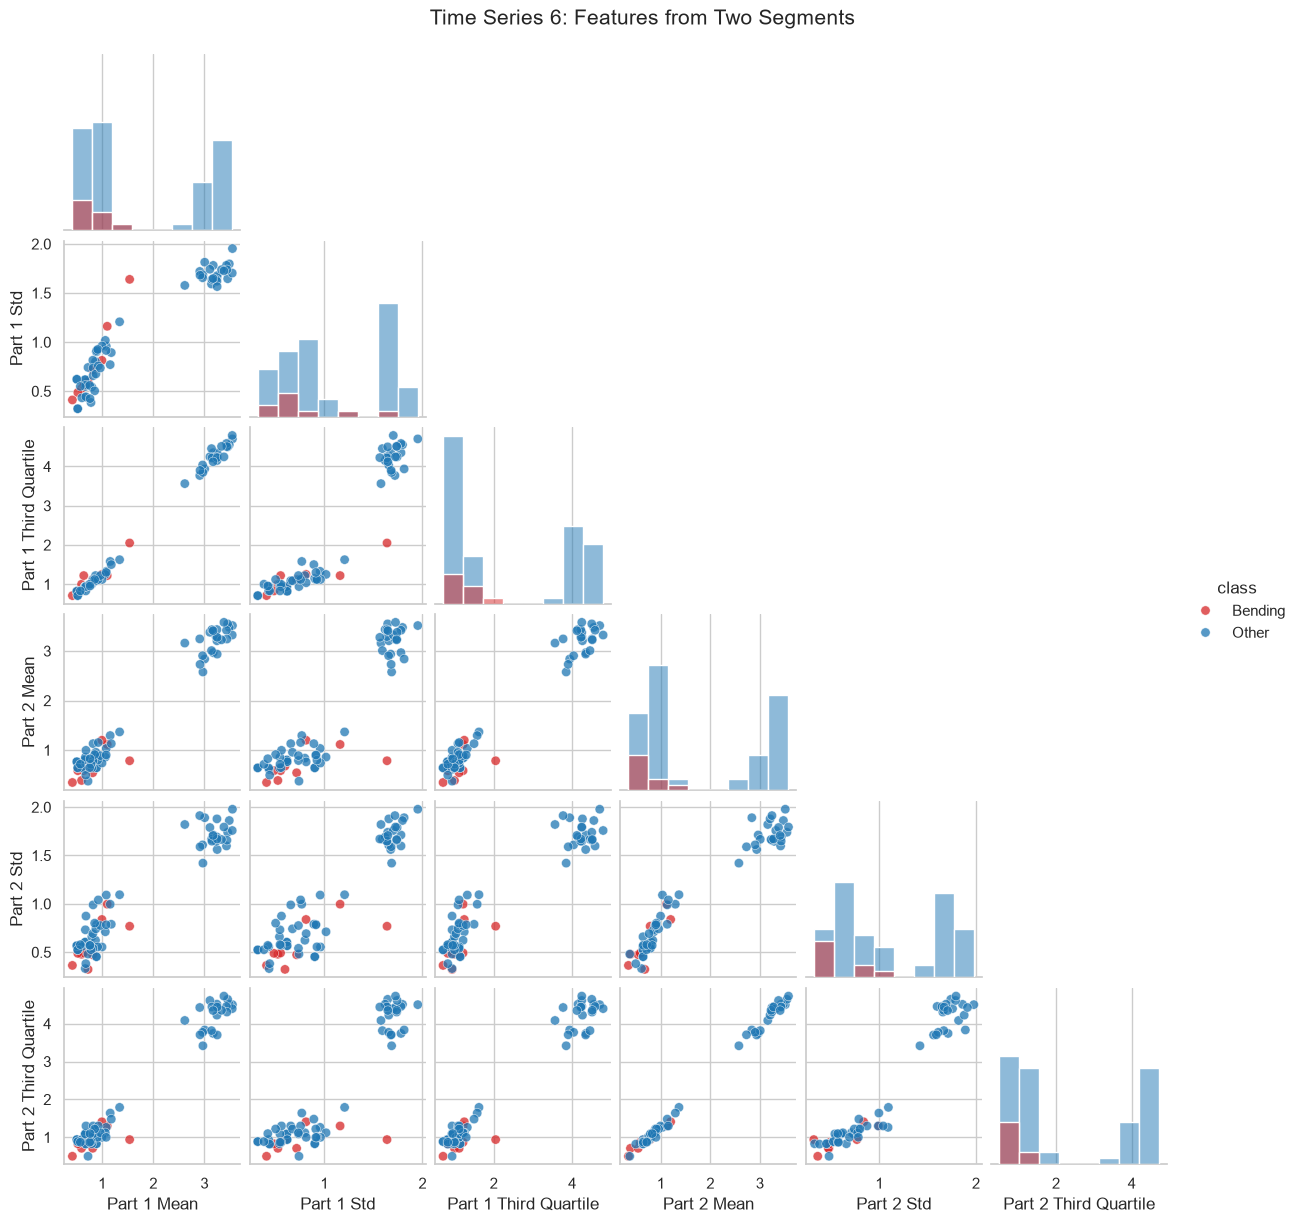

In [14]:
statistic_labels = {
    "mean": "Mean",
    "std": "Std",
    "3rd_quart": "Third Quartile"
}

for series_number in series_numbers:
    current_features = [
        f"{stat}{series_number}_part{part}"
        for part in [1, 2]
        for stat in selected_feature_types
    ]

    rename_map = {
        f"{stat}{series_number}_part{part}":
            f"Part {part} {statistic_labels[stat]}"
        for part in [1, 2]
        for stat in selected_feature_types
    }

    current_plot_df = segmented_train_df[
        current_features + ["class"]
    ].rename(columns=rename_map)

    plot_variables = [
        rename_map[feature]
        for feature in current_features
    ]

    grid = sns.pairplot(
        data=current_plot_df,
        vars=plot_variables,
        hue="class",
        hue_order=["Bending", "Other"],
        palette={
            "Bending": "#d62728",
            "Other": "#1f77b4"
        },
        diag_kind="hist",
        corner=True,
        height=2,
        plot_kws={
            "alpha": 0.75,
            "s": 45,
            "edgecolor": "white",
            "linewidth": 0.4
        }
    )

    grid.fig.suptitle(
        f"Time Series {series_number}: Features from Two Segments",
        y=1.02,
        fontsize=15
    )

    plt.show()

There is no considerable difference from 2(a)i. The features from the two halves of each series closely track each other (points lie near the diagonal in the Part 1 vs. Part 2 panels), so the halves carry largely the same information as the whole series. Bending still overlaps with the other static activities on time series 2 and 6, and time series 1 remains the most useful for bending, with only slightly more spread between the halves.

#### iii. Time Series Segments

In [15]:
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [16]:
y_binary = np.array([
    1 if item["activity"] in ["bending1", "bending2"] else 0
    for item in train_instances
])

for fold, (train_index, validation_index) in enumerate(
    stratified_cv.split(np.zeros(len(y_binary)), y_binary),
    start=1
):
    train_counts = np.bincount(
        y_binary[train_index],
        minlength=2
    )

    validation_counts = np.bincount(
        y_binary[validation_index],
        minlength=2
    )

    print(
        f"Fold {fold}: "
        f"train other/bending = {train_counts.tolist()}, "
        f"validation other/bending = {validation_counts.tolist()}"
    )

Fold 1: train other/bending = [48, 7], validation other/bending = [12, 2]
Fold 2: train other/bending = [48, 7], validation other/bending = [12, 2]
Fold 3: train other/bending = [48, 7], validation other/bending = [12, 2]
Fold 4: train other/bending = [48, 7], validation other/bending = [12, 2]
Fold 5: train other/bending = [48, 8], validation other/bending = [12, 1]


In [17]:
search_results = []
selected_features_by_l = {}

for l in range(1, 21):
    X_l, activity_l, feature_names = prepare_segmented_data(
        train_instances,
        l
    )

    y_l = to_binary(activity_l)

    # Very large C makes the L2 penalty negligible.
    logistic_pipeline = Pipeline([
        ("scale", StandardScaler()),
        (
            "logistic",
            LogisticRegression(
                C=1_000_000,
                solver="lbfgs",
                max_iter=5000,
                random_state=42
            )
        )
    ])

    selector = RFECV(
        estimator=logistic_pipeline,
        step=1,
        min_features_to_select=1,
        cv=stratified_cv,
        scoring="roc_auc",
        n_jobs=-1,
        importance_getter="named_steps.logistic.coef_"
    )

    selector.fit(X_l, y_l)

    selected_names = list(
        np.array(feature_names)[selector.support_]
    )

    number_of_features = selector.cv_results_["n_features"]
    chosen_index = np.where(
        number_of_features == selector.n_features_
    )[0][0]

    mean_auc = selector.cv_results_[
        "mean_test_score"
    ][chosen_index]

    std_auc = selector.cv_results_[
        "std_test_score"
    ][chosen_index]

    search_results.append({
        "l": l,
        "p": selector.n_features_,
        "total_candidate_features": len(feature_names),
        "mean_cv_auc": mean_auc,
        "std_cv_auc": std_auc
    })

    selected_features_by_l[l] = selected_names

    print(
        f"l={l:2d}, "
        f"p={selector.n_features_:3d}, "
        f"CV AUC={mean_auc:.4f}"
    )

l= 1, p= 18, CV AUC=1.0000
l= 2, p=  6, CV AUC=1.0000
l= 3, p=  1, CV AUC=0.9917
l= 4, p=  1, CV AUC=0.9917
l= 5, p=  1, CV AUC=1.0000
l= 6, p=  2, CV AUC=0.9833
l= 7, p=  2, CV AUC=1.0000
l= 8, p= 20, CV AUC=0.9833
l= 9, p=  2, CV AUC=0.9583
l=10, p=  5, CV AUC=1.0000
l=11, p=  1, CV AUC=0.9917
l=12, p=  1, CV AUC=0.9917
l=13, p= 26, CV AUC=0.9833
l=14, p=  8, CV AUC=0.9833
l=15, p= 39, CV AUC=0.9833
l=16, p= 11, CV AUC=0.9750
l=17, p=  1, CV AUC=0.9917
l=18, p=  2, CV AUC=1.0000
l=19, p=  1, CV AUC=1.0000
l=20, p=  3, CV AUC=1.0000


In [18]:
cv_results_df = pd.DataFrame(search_results)

cv_results_df.round({
    "mean_cv_auc": 4,
    "std_cv_auc": 4
})

,l,p,total_candidate_features,mean_cv_auc,std_cv_auc
0,1,18,42,1.0000,0.0000
1,2,6,84,1.0000,0.0000
2,3,1,126,0.9917,0.0167
3,4,1,168,0.9917,0.0167
4,5,1,210,1.0000,0.0000
5,6,2,252,0.9833,0.0333
6,7,2,294,1.0000,0.0000
7,8,20,336,0.9833,0.0204
8,9,2,378,0.9583,0.0264
9,10,5,420,1.0000,0.0000


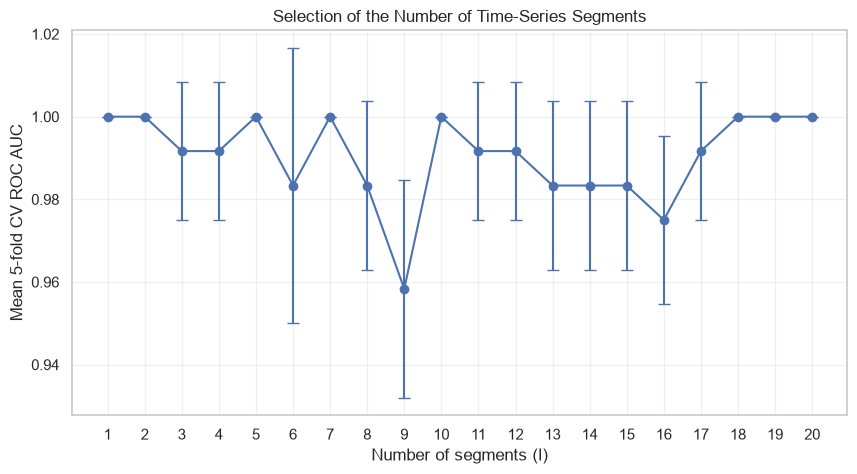

In [19]:
plt.figure(figsize=(10, 5))

plt.errorbar(
    cv_results_df["l"],
    cv_results_df["mean_cv_auc"],
    yerr=cv_results_df["std_cv_auc"],
    marker="o",
    capsize=4
)

plt.xticks(range(1, 21))
plt.xlabel("Number of segments (l)")
plt.ylabel("Mean 5-fold CV ROC AUC")
plt.title("Selection of the Number of Time-Series Segments")
plt.grid(alpha=0.3)
plt.show()

In [20]:
ranked_results = cv_results_df.sort_values(
    by=["mean_cv_auc", "p", "l"],
    ascending=[False, True, True]
).reset_index(drop=True)

best_result = ranked_results.iloc[0]

best_l = int(best_result["l"])
best_p = int(best_result["p"])
best_cv_auc = best_result["mean_cv_auc"]

best_selected_features = selected_features_by_l[best_l]

print("Best l:", best_l)
print("Best p:", best_p)
print("Best mean CV AUC:", round(best_cv_auc, 4))
print("\nSelected features:")

for feature in best_selected_features:
    print(feature)

Best l: 5
Best p: 1
Best mean CV AUC: 1.0

Selected features:
max5_part1


The best pair is $(l, p) = (5, 1)$: many pairs reach a mean CV AUC of 1.0, so ties were broken by fewer features and then smaller $l$. The single selected feature is `max5_part1`.

**Right vs. wrong way to cross-validate:** The wrong way is to select features (by p-values or RFE) using all 69 training instances and only then cross-validate the final model. The validation folds have already influenced which features were kept, so the CV score is optimistically biased. The right way is to repeat the whole selection inside every fold: scaling and RFE are fit on the training folds only, and the model is scored on the held-out fold. This is what `RFECV` with a scaling pipeline does here. Splitting each series into $l$ segments uses no information from other instances, so it can be done before cross-validation.

**Stratified cross-validation:** Bending is only 9 of the 69 training instances, so ordinary 5-fold CV could leave a fold with no bending instances. Stratified $K$-fold keeps the class proportions roughly equal in every fold; here each validation fold has 1–2 bending instances.

In [21]:
X_best_l_train, activity_best_train, _ = prepare_segmented_data(
    train_instances,
    best_l
)

X_best_train = X_best_l_train[best_selected_features]
y_best_train = to_binary(activity_best_train)

final_logistic_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            C=1_000_000,
            solver="lbfgs",
            max_iter=5000,
            random_state=42
        )
    )
])

final_logistic_model.fit(
    X_best_train,
    y_best_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['max5_part1']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [22]:
def logistic_coefficient_table(
    fitted_pipeline,
    X,
    feature_names
):
    scaler = fitted_pipeline.named_steps["scale"]
    model = fitted_pipeline.named_steps["logistic"]

    X_scaled = scaler.transform(X)

    design_matrix = np.column_stack([
        np.ones(len(X_scaled)),
        X_scaled
    ])

    probabilities = model.predict_proba(X_scaled)[:, 1]

    weights = probabilities * (1 - probabilities)
    weights = np.clip(weights, 1e-10, None)

    information_matrix = (
        design_matrix.T
        @ (design_matrix * weights[:, None])
    )

    covariance_matrix = np.linalg.pinv(
        information_matrix
    )

    standard_errors = np.sqrt(
        np.diag(covariance_matrix)
    )

    coefficients = np.concatenate([
        model.intercept_,
        model.coef_.ravel()
    ])

    z_statistics = coefficients / standard_errors

    p_values = 2 * norm.sf(
        np.abs(z_statistics)
    )

    return pd.DataFrame({
        "feature": ["intercept"] + list(feature_names),
        "coefficient": coefficients,
        "standard_error": standard_errors,
        "z_statistic": z_statistics,
        "p_value": p_values
    })

#### iv. Confusion Matrix

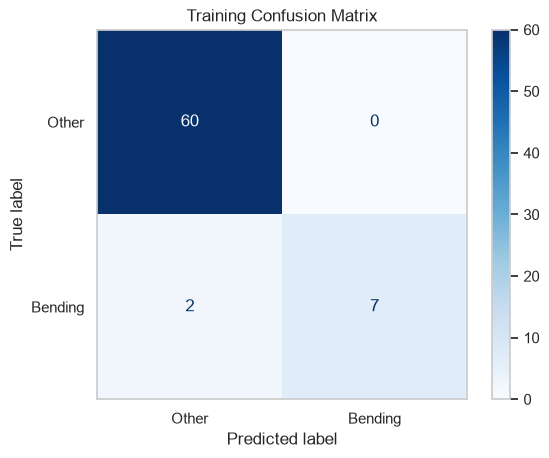

In [23]:
train_predictions = final_logistic_model.predict(
    X_best_train
)

train_probabilities = final_logistic_model.predict_proba(
    X_best_train
)[:, 1]

train_confusion_matrix = confusion_matrix(
    y_best_train,
    train_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=train_confusion_matrix,
    display_labels=["Other", "Bending"]
)

display.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Training Confusion Matrix")
plt.grid(False)
plt.show()

In [24]:
tn, fp, fn, tp = train_confusion_matrix.ravel()

train_accuracy = accuracy_score(
    y_best_train,
    train_predictions
)

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)
print(f"Training accuracy: {train_accuracy:.4f}")

True negatives: 60
False positives: 0
False negatives: 2
True positives: 7
Training accuracy: 0.9710


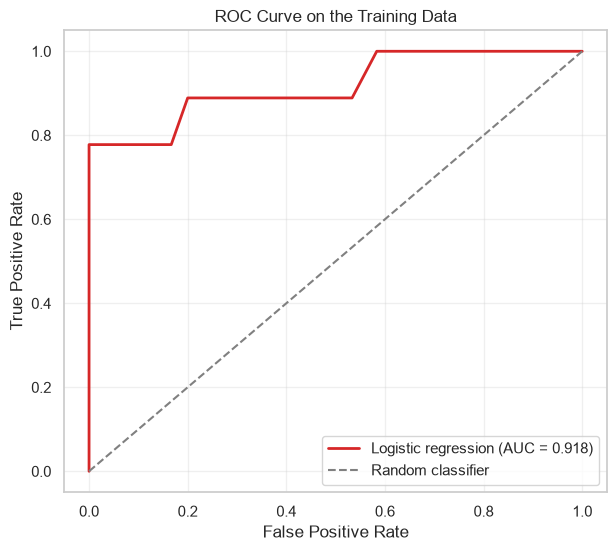

Training AUC: 0.9176


In [25]:
false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_best_train,
    train_probabilities
)

train_auc = roc_auc_score(
    y_best_train,
    train_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    color="#d62728",
    linewidth=2,
    label=f"Logistic regression (AUC = {train_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on the Training Data")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"Training AUC: {train_auc:.4f}")

In [26]:
coefficient_table = logistic_coefficient_table(
    fitted_pipeline=final_logistic_model,
    X=X_best_train,
    feature_names=best_selected_features
)

coefficient_table.insert(
    0,
    "parameter",
    [
        r"$\beta_0$"
    ] + [
        rf"$\beta_{{{i}}}$"
        for i in range(1, len(coefficient_table))
    ]
)

coefficient_table[
    [
        "parameter",
        "feature",
        "coefficient",
        "standard_error",
        "z_statistic",
        "p_value"
    ]
].round(4)

,parameter,feature,coefficient,standard_error,z_statistic,p_value
0,$\beta_0$,intercept,-3.8502,0.9195,-4.1875,0.0000
1,$\beta_{1}$,max5_part1,3.5732,1.1069,3.2282,0.0012


On the training data, the model ($l = 5$, $p = 1$, feature `max5_part1`) misses 2 of the 9 bending instances (TN = 60, FP = 0, FN = 2, TP = 7), giving a training accuracy of 0.971 and a training AUC of 0.918. Both parameters are significant: $\beta_0 = -3.85$ ($p < 0.001$) and $\beta_1 = 3.57$ ($p = 0.001$, on the standardized feature).

#### v. Test Classifier

In [27]:
X_best_l_test, activity_best_test, _ = prepare_segmented_data(
    test_instances,
    best_l
)

X_best_test = X_best_l_test[best_selected_features]
y_best_test = to_binary(activity_best_test)

print("Test feature shape:", X_best_test.shape)
print("Test class counts:", y_best_test.value_counts().sort_index().to_dict())

Test feature shape: (19, 1)
Test class counts: {0: 15, 1: 4}


In [28]:
test_predictions = final_logistic_model.predict(
    X_best_test
)

test_probabilities = final_logistic_model.predict_proba(
    X_best_test
)[:, 1]

test_accuracy = accuracy_score(
    y_best_test,
    test_predictions
)

test_auc = roc_auc_score(
    y_best_test,
    test_probabilities
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test ROC AUC: {test_auc:.4f}")

Test accuracy: 0.8947
Test ROC AUC: 0.8667


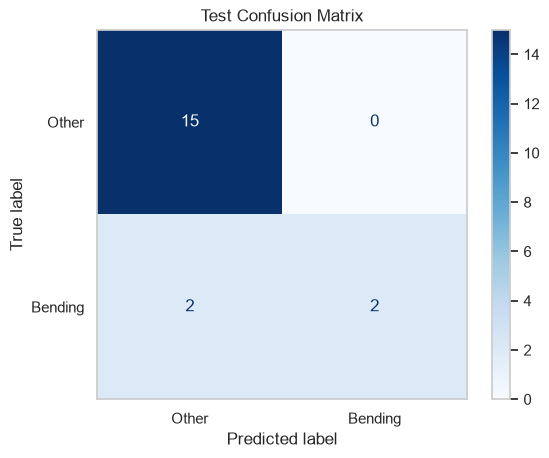

              precision    recall  f1-score   support

       Other     0.8824    1.0000    0.9375        15
     Bending     1.0000    0.5000    0.6667         4

    accuracy                         0.8947        19
   macro avg     0.9412    0.7500    0.8021        19
weighted avg     0.9071    0.8947    0.8805        19



In [29]:
test_confusion_matrix = confusion_matrix(
    y_best_test,
    test_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=["Other", "Bending"]
)

display.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Test Confusion Matrix")
plt.grid(False)
plt.show()

print(
    classification_report(
        y_best_test,
        test_predictions,
        target_names=["Other", "Bending"],
        digits=4,
        zero_division=0
    )
)

In [30]:
rfe_estimator = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            C=1_000_000,
            solver="lbfgs",
            max_iter=5000,
            random_state=42
        )
    )
])

fixed_rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=best_p,
    step=1,
    importance_getter="named_steps.logistic.coef_"
)

cv_accuracy_pipeline = Pipeline([
    ("feature_selection", fixed_rfe),
    ("scale", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            C=1_000_000,
            solver="lbfgs",
            max_iter=5000,
            random_state=42
        )
    )
])

In [31]:
# CV accuracy for the chosen (l, p), with RFE repeated inside each fold
cv_accuracy_scores = cross_val_score(
    cv_accuracy_pipeline,
    X_best_l_train,
    y_best_train,
    cv=stratified_cv,
    scoring="accuracy",
    n_jobs=-1
)

rfe_cv_accuracy = cv_accuracy_scores.mean()

print("Fold accuracies:", np.round(cv_accuracy_scores, 4))
print(f"CV accuracy: {rfe_cv_accuracy:.4f} | Test accuracy: {test_accuracy:.4f}")

Fold accuracies: [0.9286 0.9286 0.9286 1.     1.    ]
CV accuracy: 0.9571 | Test accuracy: 0.8947


The test series were split into the same $l = 5$ segments, and the trained model was applied without refitting. The test accuracy (0.895) is lower than the cross-validation accuracy (0.957) because 2 of the 4 bending test instances were missed. With only 19 test instances, one misclassification changes the accuracy by about 5%, so the gap is small.

#### vi. Separation

In [32]:
decision_scores = final_logistic_model.decision_function(
    X_best_train
)

signed_margins = (
    (2 * y_best_train.to_numpy() - 1)
    * decision_scores
)

perfect_training_separation = np.all(
    signed_margins > 0
)

coefficients = (
    final_logistic_model
    .named_steps["logistic"]
    .coef_
    .ravel()
)

print(
    "Perfect training separation:",
    perfect_training_separation
)
print(
    "Smallest signed margin:",
    signed_margins.min()
)
print(
    "Largest absolute coefficient:",
    np.abs(coefficients).max()
)
print(
    "Smallest predicted probability:",
    train_probabilities.min()
)
print(
    "Largest predicted probability:",
    train_probabilities.max()
)

Perfect training separation: False
Smallest signed margin: -3.9758390595552386
Largest absolute coefficient: 3.5732179859245683
Smallest predicted probability: 7.594979779931477e-07
Largest predicted probability: 0.9963053334070809


Yes. Many values of $l$ reach a mean CV AUC of 1.0, so with enough features the classes are nearly linearly separable. Under (near-)separation, the maximum-likelihood coefficients grow very large, which makes the estimates and their p-values unstable. The final one-feature model is not perfectly separated (2 training errors, smallest signed margin < 0), so its coefficients stay finite, but the near-separation means they should be interpreted with caution.

#### vii. Imbalance

In [33]:
rng = np.random.default_rng(42)

case_indices = y_best_train[
    y_best_train == 1
].index.to_numpy()

control_indices = y_best_train[
    y_best_train == 0
].index.to_numpy()

sampled_control_indices = rng.choice(
    control_indices,
    size=len(case_indices),
    replace=False
)

case_control_indices = np.concatenate([
    case_indices,
    sampled_control_indices
])

rng.shuffle(case_control_indices)

X_case_control = X_best_train.loc[
    case_control_indices
]

y_case_control = y_best_train.loc[
    case_control_indices
]

print("Original training distribution:")
print(y_best_train.value_counts().sort_index())

print("\nCase-control distribution:")
print(y_case_control.value_counts().sort_index())

Original training distribution:
activity
0    60
1     9
Name: count, dtype: int64

Case-control distribution:
activity
0    9
1    9
Name: count, dtype: int64


In [34]:
case_control_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            C=1_000_000,
            solver="lbfgs",
            max_iter=5000,
            random_state=42
        )
    )
])

case_control_model.fit(
    X_case_control,
    y_case_control
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['max5_part1']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [35]:
population_prevalence = y_best_train.mean()
sample_prevalence = y_case_control.mean()

intercept_adjustment = (
    np.log(
        population_prevalence
        / (1 - population_prevalence)
    )
    -
    np.log(
        sample_prevalence
        / (1 - sample_prevalence)
    )
)

sample_intercept = (
    case_control_model
    .named_steps["logistic"]
    .intercept_[0]
)

adjusted_intercept = (
    sample_intercept + intercept_adjustment
)

print(
    "Original training prevalence:",
    round(population_prevalence, 4)
)
print(
    "Case-control prevalence:",
    round(sample_prevalence, 4)
)
print(
    "Intercept adjustment:",
    round(intercept_adjustment, 4)
)
print(
    "Sample intercept:",
    round(sample_intercept, 4)
)
print(
    "Adjusted intercept:",
    round(adjusted_intercept, 4)
)

Original training prevalence: 0.1304
Case-control prevalence: 0.5
Intercept adjustment: -1.8971
Sample intercept: 0.1135
Adjusted intercept: -1.7836


In [36]:
case_control_coefficients = (
    case_control_model
    .named_steps["logistic"]
    .coef_
    .ravel()
)

adjusted_parameter_table = pd.DataFrame({
    "parameter": [
        r"$\beta_0$"
    ] + [
        rf"$\beta_{{{i}}}$"
        for i in range(
            1,
            len(case_control_coefficients) + 1
        )
    ],
    "feature": [
        "intercept"
    ] + list(best_selected_features),
    "sample_coefficient": np.concatenate([
        [sample_intercept],
        case_control_coefficients
    ]),
    "adjusted_coefficient": np.concatenate([
        [adjusted_intercept],
        case_control_coefficients
    ])
})

adjusted_parameter_table.round(4)

,parameter,feature,sample_coefficient,adjusted_coefficient
0,$\beta_0$,intercept,0.1135,-1.7836
1,$\beta_{1}$,max5_part1,2.3563,2.3563


In [37]:
def adjusted_case_control_predictions(
    fitted_model,
    X,
    intercept_adjustment,
    threshold=0.5
):
    unadjusted_logits = (
        fitted_model.decision_function(X)
    )

    adjusted_logits = (
        unadjusted_logits
        + intercept_adjustment
    )

    adjusted_probabilities = expit(
        adjusted_logits
    )

    adjusted_predictions = (
        adjusted_probabilities >= threshold
    ).astype(int)

    return adjusted_predictions, adjusted_probabilities

In [38]:
cc_train_predictions, cc_train_probabilities = (
    adjusted_case_control_predictions(
        case_control_model,
        X_best_train,
        intercept_adjustment
    )
)

cc_train_matrix = confusion_matrix(
    y_best_train,
    cc_train_predictions,
    labels=[0, 1]
)

cc_train_accuracy = accuracy_score(
    y_best_train,
    cc_train_predictions
)

cc_train_auc = roc_auc_score(
    y_best_train,
    cc_train_probabilities
)

print("Training confusion matrix:")
print(cc_train_matrix)
print(f"Training accuracy: {cc_train_accuracy:.4f}")
print(f"Training AUC: {cc_train_auc:.4f}")

Training confusion matrix:
[[60  0]
 [ 4  5]]
Training accuracy: 0.9420
Training AUC: 0.9176


In [39]:
cc_test_predictions, cc_test_probabilities = (
    adjusted_case_control_predictions(
        case_control_model,
        X_best_test,
        intercept_adjustment
    )
)

cc_test_matrix = confusion_matrix(
    y_best_test,
    cc_test_predictions,
    labels=[0, 1]
)

cc_test_accuracy = accuracy_score(
    y_best_test,
    cc_test_predictions
)

cc_test_auc = roc_auc_score(
    y_best_test,
    cc_test_probabilities
)

print("Test confusion matrix:")
print(cc_test_matrix)
print(f"Test accuracy: {cc_test_accuracy:.4f}")
print(f"Test AUC: {cc_test_auc:.4f}")

Test confusion matrix:
[[15  0]
 [ 2  2]]
Test accuracy: 0.8947
Test AUC: 0.8667


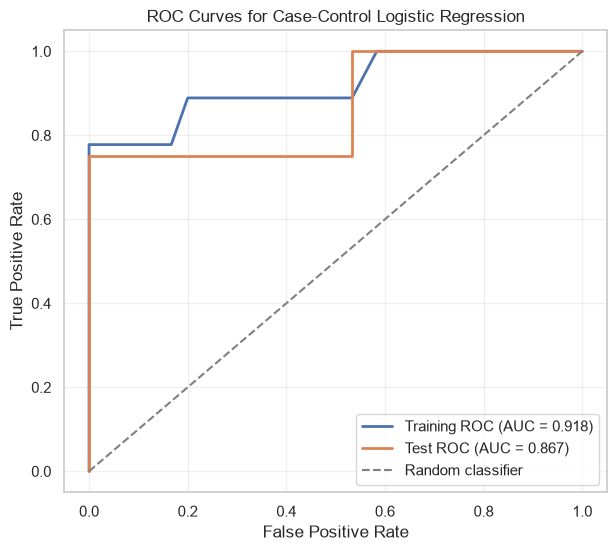

In [40]:
cc_train_fpr, cc_train_tpr, _ = roc_curve(
    y_best_train,
    cc_train_probabilities
)

cc_test_fpr, cc_test_tpr, _ = roc_curve(
    y_best_test,
    cc_test_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    cc_train_fpr,
    cc_train_tpr,
    linewidth=2,
    label=f"Training ROC (AUC = {cc_train_auc:.3f})"
)

plt.plot(
    cc_test_fpr,
    cc_test_tpr,
    linewidth=2,
    label=f"Test ROC (AUC = {cc_test_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Case-Control Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

Yes, the classes are imbalanced: 9 bending vs. 60 other instances (13% bending), and most errors in the confusion matrices are missed bending instances. For case-control sampling, all 9 bending cases were kept and 9 controls were sampled at random. The intercept was then adjusted by

$$\log\frac{\pi}{1-\pi} - \log\frac{\tilde{\pi}}{1-\tilde{\pi}} = \log\frac{9/69}{60/69} - \log\frac{9/18}{9/18} \approx -1.897,$$

moving it from 0.114 to −1.784; the slope is unchanged. The adjusted model has a training accuracy of 0.942 (AUC 0.918) and a test accuracy of 0.895 (AUC 0.867). The AUC does not change with the intercept shift because shifting every logit by the same constant does not change the ranking of the predictions.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [41]:
C_values = np.logspace(
    -4,
    4,
    25
)

In [42]:
l1_search_results = []
l1_selected_features_by_l = {}

for l in range(1, 21):
    X_l, activity_l, feature_names = prepare_segmented_data(
        train_instances,
        l
    )

    y_l = to_binary(activity_l)

    l1_pipeline = Pipeline([
        ("scale", StandardScaler()),
        (
            "logistic",
            LogisticRegression(
                l1_ratio=1.0,
                solver="liblinear",
                max_iter=5000,
                random_state=42
            )
        )
    ])

    parameter_grid = {
        "logistic__C": C_values
    }

    grid_search = GridSearchCV(
        estimator=l1_pipeline,
        param_grid=parameter_grid,
        scoring={
            "roc_auc": "roc_auc",
            "accuracy": "accuracy"
        },
        refit="roc_auc",
        cv=stratified_cv,
        n_jobs=-1,
        return_train_score=False
    )

    grid_search.fit(X_l, y_l)

    best_index = grid_search.best_index_
    best_C_for_l = grid_search.best_params_[
        "logistic__C"
    ]

    fitted_coefficients = (
        grid_search.best_estimator_
        .named_steps["logistic"]
        .coef_
        .ravel()
    )

    nonzero_mask = ~np.isclose(
        fitted_coefficients,
        0.0,
        atol=1e-10
    )

    selected_names = list(
        np.array(feature_names)[nonzero_mask]
    )

    number_selected = int(nonzero_mask.sum())

    mean_cv_auc = grid_search.cv_results_[
        "mean_test_roc_auc"
    ][best_index]

    std_cv_auc = grid_search.cv_results_[
        "std_test_roc_auc"
    ][best_index]

    mean_cv_accuracy = grid_search.cv_results_[
        "mean_test_accuracy"
    ][best_index]

    std_cv_accuracy = grid_search.cv_results_[
        "std_test_accuracy"
    ][best_index]

    l1_search_results.append({
        "l": l,
        "C": best_C_for_l,
        "lambda_approx": 1 / best_C_for_l,
        "total_features": len(feature_names),
        "selected_features": number_selected,
        "mean_cv_auc": mean_cv_auc,
        "std_cv_auc": std_cv_auc,
        "mean_cv_accuracy": mean_cv_accuracy,
        "std_cv_accuracy": std_cv_accuracy
    })

    l1_selected_features_by_l[l] = selected_names

    print(
        f"l={l:2d}, "
        f"C={best_C_for_l:.6g}, "
        f"nonzero={number_selected:3d}, "
        f"CV AUC={mean_cv_auc:.4f}, "
        f"CV accuracy={mean_cv_accuracy:.4f}"
    )

l= 1, C=4.64159, nonzero=  8, CV AUC=1.0000, CV accuracy=0.9571
l= 2, C=10, nonzero= 11, CV AUC=1.0000, CV accuracy=0.9714
l= 3, C=46.4159, nonzero= 13, CV AUC=1.0000, CV accuracy=0.9429
l= 4, C=0.1, nonzero=  2, CV AUC=0.9917, CV accuracy=0.8703
l= 5, C=464.159, nonzero= 35, CV AUC=0.9917, CV accuracy=0.9275
l= 6, C=100, nonzero= 22, CV AUC=1.0000, CV accuracy=0.9571
l= 7, C=0.215443, nonzero=  5, CV AUC=0.9917, CV accuracy=0.9275
l= 8, C=2154.43, nonzero=102, CV AUC=0.9833, CV accuracy=0.9429
l= 9, C=1, nonzero= 13, CV AUC=0.9917, CV accuracy=0.9275
l=10, C=100, nonzero= 34, CV AUC=1.0000, CV accuracy=0.9714
l=11, C=0.464159, nonzero=  7, CV AUC=0.9917, CV accuracy=0.9132
l=12, C=0.215443, nonzero=  4, CV AUC=1.0000, CV accuracy=0.9429
l=13, C=0.1, nonzero=  2, CV AUC=1.0000, CV accuracy=0.9132
l=14, C=0.1, nonzero=  2, CV AUC=1.0000, CV accuracy=0.9132
l=15, C=2154.43, nonzero=155, CV AUC=0.9833, CV accuracy=0.9429
l=16, C=1, nonzero= 17, CV AUC=0.9833, CV accuracy=0.8989
l=17, C=2.

In [43]:
l1_results_df = pd.DataFrame(
    l1_search_results
)

l1_results_df.round({
    "C": 6,
    "lambda_approx": 6,
    "mean_cv_auc": 4,
    "std_cv_auc": 4,
    "mean_cv_accuracy": 4,
    "std_cv_accuracy": 4
})

,l,C,lambda_approx,total_features,selected_features,mean_cv_auc,std_cv_auc,mean_cv_accuracy,std_cv_accuracy
0,1,4.641589,0.215443,42,8,1.0000,0.0000,0.9571,0.0350
1,2,10.000000,0.100000,84,11,1.0000,0.0000,0.9714,0.0350
2,3,46.415888,0.021544,126,13,1.0000,0.0000,0.9429,0.0286
3,4,0.100000,10.000000,168,2,0.9917,0.0167,0.8703,0.0264
4,5,464.158883,0.002154,210,35,0.9917,0.0167,0.9275,0.0452
5,6,100.000000,0.010000,252,22,1.0000,0.0000,0.9571,0.0350
6,7,0.215443,4.641589,294,5,0.9917,0.0167,0.9275,0.0452
7,8,2154.434690,0.000464,336,102,0.9833,0.0204,0.9429,0.0535
8,9,1.000000,1.000000,378,13,0.9917,0.0167,0.9275,0.0452
9,10,100.000000,0.010000,420,34,1.0000,0.0000,0.9714,0.0350


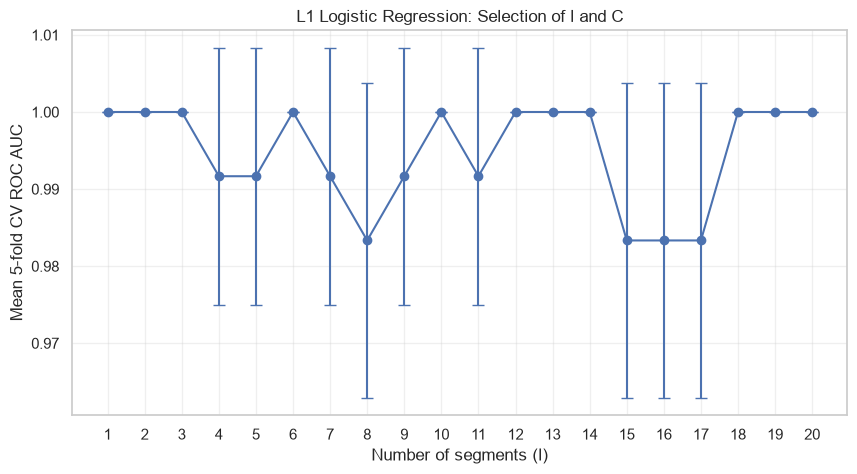

In [44]:
plt.figure(figsize=(10, 5))

plt.errorbar(
    l1_results_df["l"],
    l1_results_df["mean_cv_auc"],
    yerr=l1_results_df["std_cv_auc"],
    marker="o",
    capsize=4
)

plt.xticks(range(1, 21))
plt.xlabel("Number of segments (l)")
plt.ylabel("Mean 5-fold CV ROC AUC")
plt.title("L1 Logistic Regression: Selection of l and C")
plt.grid(alpha=0.3)
plt.show()

In [45]:
l1_ranked_results = l1_results_df.sort_values(
    by=[
        "mean_cv_auc",
        "selected_features",
        "l"
    ],
    ascending=[
        False,
        True,
        True
    ]
).reset_index(drop=True)

l1_best_result = l1_ranked_results.iloc[0]

l1_best_l = int(
    l1_best_result["l"]
)

l1_best_C = float(
    l1_best_result["C"]
)

l1_best_p = int(
    l1_best_result["selected_features"]
)

l1_best_cv_auc = float(
    l1_best_result["mean_cv_auc"]
)

l1_best_cv_accuracy = float(
    l1_best_result["mean_cv_accuracy"]
)

print("Best l:", l1_best_l)
print("Best C:", l1_best_C)
print("Approximate lambda:", 1 / l1_best_C)
print("Number of selected features:", l1_best_p)
print("Mean CV AUC:", round(l1_best_cv_auc, 4))
print(
    "Mean CV accuracy:",
    round(l1_best_cv_accuracy, 4)
)

Best l: 13
Best C: 0.1
Approximate lambda: 10.0
Number of selected features: 2
Mean CV AUC: 1.0
Mean CV accuracy: 0.9132


In [46]:
X_l1_train, activity_l1_train, l1_all_feature_names = prepare_segmented_data(
    train_instances,
    l1_best_l
)

y_l1_train = to_binary(activity_l1_train)

In [47]:
l1_final_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            l1_ratio=1.0,
            solver="liblinear",
            C=l1_best_C,
            max_iter=5000,
            random_state=42
        )
    )
])

l1_final_model.fit(
    X_l1_train,
    y_l1_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](546,)","['min1_part1','max1_part1','mean1_part1',...,'std6_part13', '1st_quart6_part13','3rd_quart6_part13']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,546
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [48]:
l1_coefficients = (
    l1_final_model
    .named_steps["logistic"]
    .coef_
    .ravel()
)

l1_coefficient_df = pd.DataFrame({
    "feature": l1_all_feature_names,
    "coefficient": l1_coefficients
})

l1_selected_feature_df = (
    l1_coefficient_df[
        ~np.isclose(
            l1_coefficient_df["coefficient"],
            0.0,
            atol=1e-10
        )
    ]
    .copy()
    .sort_values(
        "coefficient",
        key=np.abs,
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Number of candidate features:",
    len(l1_all_feature_names)
)

print(
    "Number of selected features:",
    len(l1_selected_feature_df)
)

l1_selected_feature_df

Number of candidate features: 546
Number of selected features: 2


,feature,coefficient
0,min5_part2,0.355483
1,1st_quart5_part2,0.179824


For each $l$, the budget $C$ was tuned over 25 values from $10^{-4}$ to $10^{4}$ with stratified 5-fold CV, with standardization inside the pipeline. The best setting is $l = 13$ and $C = 0.1$ ($\lambda \approx 10$), chosen by CV AUC (ties broken by fewer nonzero coefficients). It keeps only 2 of the 546 features (`min5_part2` and `1st_quart5_part2`), with a mean CV AUC of 1.0 and a CV accuracy of 0.913.

#### ii. Comparison

In [49]:
X_l1_test, activity_l1_test, _ = prepare_segmented_data(
    test_instances,
    l1_best_l
)

y_l1_test = to_binary(activity_l1_test)

In [50]:
l1_train_predictions = l1_final_model.predict(
    X_l1_train
)

l1_train_probabilities = l1_final_model.predict_proba(
    X_l1_train
)[:, 1]

l1_test_predictions = l1_final_model.predict(
    X_l1_test
)

l1_test_probabilities = l1_final_model.predict_proba(
    X_l1_test
)[:, 1]

In [51]:
l1_train_accuracy = accuracy_score(
    y_l1_train,
    l1_train_predictions
)

l1_train_auc = roc_auc_score(
    y_l1_train,
    l1_train_probabilities
)

l1_test_accuracy = accuracy_score(
    y_l1_test,
    l1_test_predictions
)

l1_test_auc = roc_auc_score(
    y_l1_test,
    l1_test_probabilities
)

print(f"L1 training accuracy: {l1_train_accuracy:.4f}")
print(f"L1 training AUC: {l1_train_auc:.4f}")
print(f"L1 test accuracy: {l1_test_accuracy:.4f}")
print(f"L1 test AUC: {l1_test_auc:.4f}")

L1 training accuracy: 0.9275
L1 training AUC: 0.9926
L1 test accuracy: 0.8947
L1 test AUC: 0.9500


In [52]:
model_comparison = pd.DataFrame({
    "model": [
        "Unpenalized Logistic + RFE",
        "L1-Penalized Logistic"
    ],
    "l": [
        best_l,
        l1_best_l
    ],
    "selected_features": [
        best_p,
        l1_best_p
    ],
    "cv_accuracy": [
        rfe_cv_accuracy,
        l1_best_cv_accuracy
    ],
    "cv_auc": [
        best_cv_auc,
        l1_best_cv_auc
    ],
    "train_accuracy": [
        train_accuracy,
        l1_train_accuracy
    ],
    "train_auc": [
        train_auc,
        l1_train_auc
    ],
    "test_accuracy": [
        test_accuracy,
        l1_test_accuracy
    ],
    "test_auc": [
        test_auc,
        l1_test_auc
    ]
})

model_comparison.round(4)

,model,l,selected_features,cv_accuracy,cv_auc,train_accuracy,train_auc,test_accuracy,test_auc
0,Unpenalized Logistic + RFE,5,1,0.9571,1.0,0.9710,0.9176,0.8947,0.8667
1,L1-Penalized Logistic,13,2,0.9132,1.0,0.9275,0.9926,0.8947,0.9500


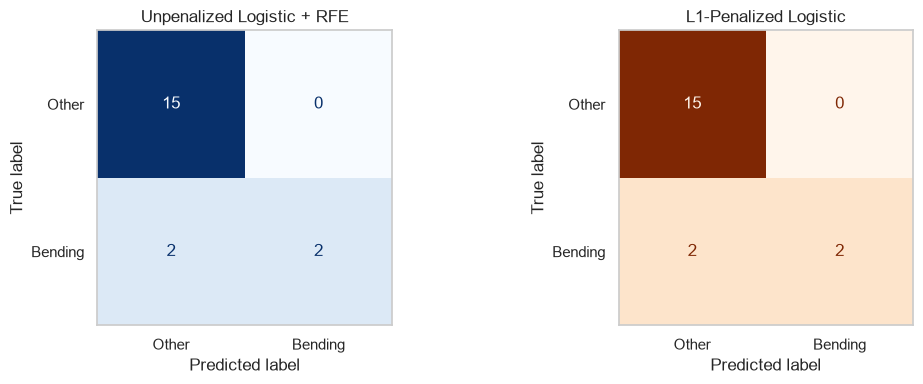

In [53]:
unpenalized_test_matrix = confusion_matrix(
    y_best_test,
    test_predictions,
    labels=[0, 1]
)

l1_test_matrix = confusion_matrix(
    y_l1_test,
    l1_test_predictions,
    labels=[0, 1]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4)
)

ConfusionMatrixDisplay(
    unpenalized_test_matrix,
    display_labels=["Other", "Bending"]
).plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title(
    "Unpenalized Logistic + RFE"
)
axes[0].grid(False)

ConfusionMatrixDisplay(
    l1_test_matrix,
    display_labels=["Other", "Bending"]
).plot(
    ax=axes[1],
    cmap="Oranges",
    values_format="d",
    colorbar=False
)

axes[1].set_title(
    "L1-Penalized Logistic"
)
axes[1].grid(False)

plt.tight_layout()
plt.show()

Both models reach a test accuracy of 0.895, but the L1-penalized model has the higher test AUC (0.950 vs. 0.867), so it performs slightly better; with only 19 test instances the difference is small. L1 is also easier to implement: a single penalized fit selects and estimates the coefficients together, with only $C$ to tune. Selection by p-values or RFE needs a separate, iterative elimination loop that must be repeated inside cross-validation.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [54]:
multiclass_train_labels = pd.Series([
    item["activity"]
    for item in train_instances
])

multiclass_train_labels.value_counts().sort_index()

bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64

In [55]:
multiclass_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

In [56]:
multiclass_search_results = []

for l in range(1, 21):
    X_l, activity_l, feature_names = prepare_segmented_data(
        train_instances,
        l
    )
    y_l = activity_l

    multinomial_pipeline = Pipeline([
        ("scale", StandardScaler()),
        (
            "logistic",
            LogisticRegression(
                l1_ratio=1.0,
                solver="saga",
                max_iter=10_000,
                random_state=42
            )
        )
    ])

    grid_search = GridSearchCV(
        estimator=multinomial_pipeline,
        param_grid={
            "logistic__C": C_values
        },
        scoring={
            "accuracy": "accuracy",
            "macro_auc": "roc_auc_ovr"
        },
        refit="accuracy",
        cv=multiclass_cv,
        n_jobs=-1,
        return_train_score=False
    )

    grid_search.fit(X_l, y_l)

    best_index = grid_search.best_index_
    best_C_for_l = grid_search.best_params_[
        "logistic__C"
    ]

    coefficient_matrix = (
        grid_search.best_estimator_
        .named_steps["logistic"]
        .coef_
    )

    # A feature is retained if it has a nonzero coefficient
    # for at least one activity.
    nonzero_feature_mask = np.any(
        ~np.isclose(
            coefficient_matrix,
            0.0,
            atol=1e-10
        ),
        axis=0
    )

    number_selected = int(
        nonzero_feature_mask.sum()
    )

    mean_cv_accuracy = grid_search.cv_results_[
        "mean_test_accuracy"
    ][best_index]

    std_cv_accuracy = grid_search.cv_results_[
        "std_test_accuracy"
    ][best_index]

    mean_cv_macro_auc = grid_search.cv_results_[
        "mean_test_macro_auc"
    ][best_index]

    std_cv_macro_auc = grid_search.cv_results_[
        "std_test_macro_auc"
    ][best_index]

    multiclass_search_results.append({
        "l": l,
        "C": best_C_for_l,
        "lambda_approx": 1 / best_C_for_l,
        "total_features": len(feature_names),
        "selected_features": number_selected,
        "mean_cv_accuracy": mean_cv_accuracy,
        "std_cv_accuracy": std_cv_accuracy,
        "mean_cv_macro_auc": mean_cv_macro_auc,
        "std_cv_macro_auc": std_cv_macro_auc
    })

    print(
        f"l={l:2d}, "
        f"C={best_C_for_l:.6g}, "
        f"selected={number_selected:3d}, "
        f"CV accuracy={mean_cv_accuracy:.4f}, "
        f"macro AUC={mean_cv_macro_auc:.4f}"
    )

l= 1, C=10, selected= 31, CV accuracy=0.9134, macro AUC=0.9554
l= 2, C=4.64159, selected= 41, CV accuracy=0.9142, macro AUC=0.9676
l= 3, C=100, selected=124, CV accuracy=0.8415, macro AUC=0.9827
l= 4, C=1000, selected=168, CV accuracy=0.8693, macro AUC=0.9753
l= 5, C=215.443, selected=210, CV accuracy=0.8832, macro AUC=0.9857
l= 6, C=100, selected=252, CV accuracy=0.8979, macro AUC=0.9832
l= 7, C=10, selected=168, CV accuracy=0.8538, macro AUC=0.9658
l= 8, C=1000, selected=336, CV accuracy=0.8685, macro AUC=0.9810
l= 9, C=21.5443, selected=258, CV accuracy=0.8685, macro AUC=0.9653
l=10, C=100, selected=419, CV accuracy=0.8391, macro AUC=0.9714
l=11, C=46.4159, selected=440, CV accuracy=0.7672, macro AUC=0.9620
l=12, C=100, selected=504, CV accuracy=0.8554, macro AUC=0.9782
l=13, C=215.443, selected=546, CV accuracy=0.8407, macro AUC=0.9771
l=14, C=10, selected=337, CV accuracy=0.7966, macro AUC=0.9664
l=15, C=215.443, selected=630, CV accuracy=0.8685, macro AUC=0.9753
l=16, C=100, sele

In [57]:
multiclass_results_df = pd.DataFrame(
    multiclass_search_results
)

multiclass_ranked_results = (
    multiclass_results_df
    .sort_values(
        by=[
            "mean_cv_accuracy",
            "selected_features",
            "l"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
    .reset_index(drop=True)
)

multiclass_best_result = (
    multiclass_ranked_results.iloc[0]
)

multiclass_best_l = int(
    multiclass_best_result["l"]
)

multiclass_best_C = float(
    multiclass_best_result["C"]
)

multiclass_best_cv_accuracy = float(
    multiclass_best_result["mean_cv_accuracy"]
)

multiclass_best_cv_auc = float(
    multiclass_best_result["mean_cv_macro_auc"]
)

print("Best l:", multiclass_best_l)
print("Best C:", multiclass_best_C)
print(
    "Mean CV accuracy:",
    round(multiclass_best_cv_accuracy, 4)
)
print(
    "Mean CV macro AUC:",
    round(multiclass_best_cv_auc, 4)
)

Best l: 2
Best C: 4.641588833612772
Mean CV accuracy: 0.9142
Mean CV macro AUC: 0.9676


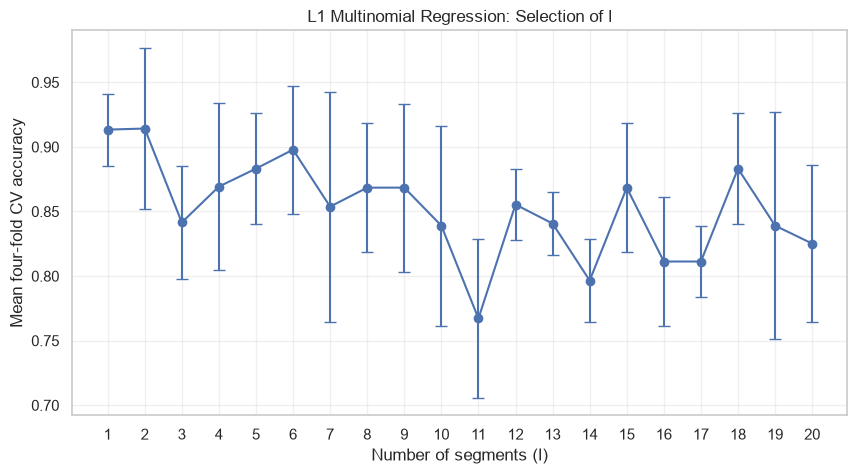

In [58]:
plt.figure(figsize=(10, 5))

plt.errorbar(
    multiclass_results_df["l"],
    multiclass_results_df["mean_cv_accuracy"],
    yerr=multiclass_results_df[
        "std_cv_accuracy"
    ],
    marker="o",
    capsize=4
)

plt.xticks(range(1, 21))
plt.xlabel("Number of segments (l)")
plt.ylabel("Mean four-fold CV accuracy")
plt.title(
    "L1 Multinomial Regression: Selection of l"
)
plt.grid(alpha=0.3)
plt.show()

In [59]:
X_multiclass_train, y_multiclass_train, multiclass_feature_names = (
    prepare_segmented_data(train_instances, multiclass_best_l)
)

In [60]:
multiclass_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            l1_ratio=1.0,
            solver="saga",
            C=multiclass_best_C,
            max_iter=10_000,
            random_state=42
        )
    )
])

multiclass_model.fit(
    X_multiclass_train,
    y_multiclass_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['bending1','bending2','cycling',...,'sitting','standing','walking']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](84,)","['min1_part1','max1_part1','mean1_part1',...,'std6_part2', '1st_quart6_part2','3rd_quart6_part2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,84
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [61]:
X_multiclass_test, y_multiclass_test, _ = prepare_segmented_data(
    test_instances,
    multiclass_best_l
)

In [62]:
multiclass_test_predictions = (
    multiclass_model.predict(
        X_multiclass_test
    )
)

multiclass_test_probabilities = (
    multiclass_model.predict_proba(
        X_multiclass_test
    )
)

multiclass_test_accuracy = accuracy_score(
    y_multiclass_test,
    multiclass_test_predictions
)

multiclass_test_error = (
    1 - multiclass_test_accuracy
)

print(
    "Test accuracy:",
    round(multiclass_test_accuracy, 4)
)

print(
    "Test error:",
    round(multiclass_test_error, 4)
)

Test accuracy: 0.8421
Test error: 0.1579


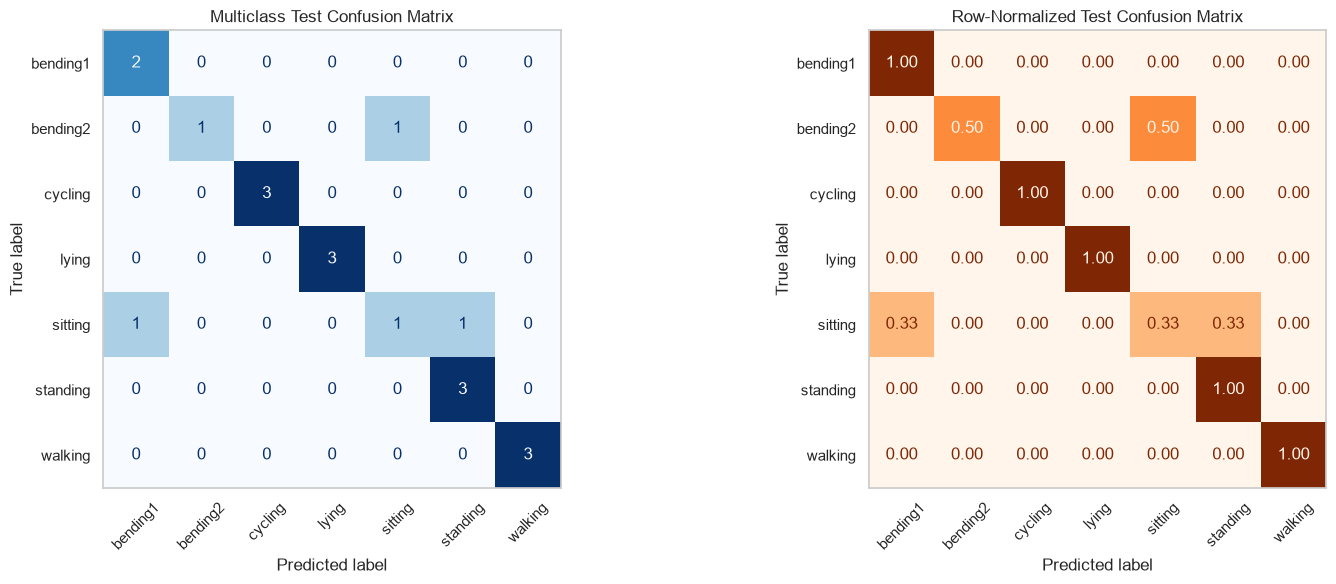

In [63]:
class_names = list(
    multiclass_model
    .named_steps["logistic"]
    .classes_
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

ConfusionMatrixDisplay.from_predictions(
    y_multiclass_test,
    multiclass_test_predictions,
    labels=class_names,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title(
    "Multiclass Test Confusion Matrix"
)
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_multiclass_test,
    multiclass_test_predictions,
    labels=class_names,
    display_labels=class_names,
    normalize="true",
    cmap="Oranges",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=False,
    ax=axes[1]
)

axes[1].set_title(
    "Row-Normalized Test Confusion Matrix"
)
axes[1].grid(False)

plt.tight_layout()
plt.show()

In [64]:
print(
    classification_report(
        y_multiclass_test,
        multiclass_test_predictions,
        labels=class_names,
        zero_division=0,
        digits=4
    )
)

              precision    recall  f1-score   support

    bending1     0.6667    1.0000    0.8000         2
    bending2     1.0000    0.5000    0.6667         2
     cycling     1.0000    1.0000    1.0000         3
       lying     1.0000    1.0000    1.0000         3
     sitting     0.5000    0.3333    0.4000         3
    standing     0.7500    1.0000    0.8571         3
     walking     1.0000    1.0000    1.0000         3

    accuracy                         0.8421        19
   macro avg     0.8452    0.8333    0.8177        19
weighted avg     0.8465    0.8421    0.8266        19



In [65]:
def calculate_multiclass_roc(
    y_true,
    probabilities,
    class_names
):
    y_binary = label_binarize(
        y_true,
        classes=class_names
    )

    fpr = {}
    tpr = {}
    auc_values = {}

    for class_index, class_name in enumerate(
        class_names
    ):
        fpr[class_name], tpr[class_name], _ = (
            roc_curve(
                y_binary[:, class_index],
                probabilities[:, class_index]
            )
        )

        auc_values[class_name] = auc(
            fpr[class_name],
            tpr[class_name]
        )

    fpr["micro"], tpr["micro"], _ = roc_curve(
        y_binary.ravel(),
        probabilities.ravel()
    )

    auc_values["micro"] = auc(
        fpr["micro"],
        tpr["micro"]
    )

    all_fpr = np.unique(
        np.concatenate([
            fpr[class_name]
            for class_name in class_names
        ])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for class_name in class_names:
        mean_tpr += np.interp(
            all_fpr,
            fpr[class_name],
            tpr[class_name]
        )

    mean_tpr /= len(class_names)

    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr

    auc_values["macro"] = auc(
        fpr["macro"],
        tpr["macro"]
    )

    return fpr, tpr, auc_values

In [66]:
def plot_multiclass_roc(
    y_true,
    probabilities,
    class_names,
    title
):
    fpr, tpr, auc_values = (
        calculate_multiclass_roc(
            y_true,
            probabilities,
            class_names
        )
    )

    plt.figure(figsize=(10, 8))

    colors = plt.cm.tab10(
        np.linspace(
            0,
            1,
            len(class_names)
        )
    )

    for class_name, color in zip(
        class_names,
        colors
    ):
        plt.plot(
            fpr[class_name],
            tpr[class_name],
            color=color,
            linewidth=1.6,
            label=(
                f"{class_name} "
                f"(AUC={auc_values[class_name]:.3f})"
            )
        )

    plt.plot(
        fpr["micro"],
        tpr["micro"],
        color="deeppink",
        linestyle=":",
        linewidth=3,
        label=(
            "Micro-average "
            f"(AUC={auc_values['micro']:.3f})"
        )
    )

    plt.plot(
        fpr["macro"],
        tpr["macro"],
        color="navy",
        linestyle="--",
        linewidth=3,
        label=(
            "Macro-average "
            f"(AUC={auc_values['macro']:.3f})"
        )
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Random classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(
        loc="lower right",
        fontsize=9
    )
    plt.grid(alpha=0.3)
    plt.show()

    return auc_values

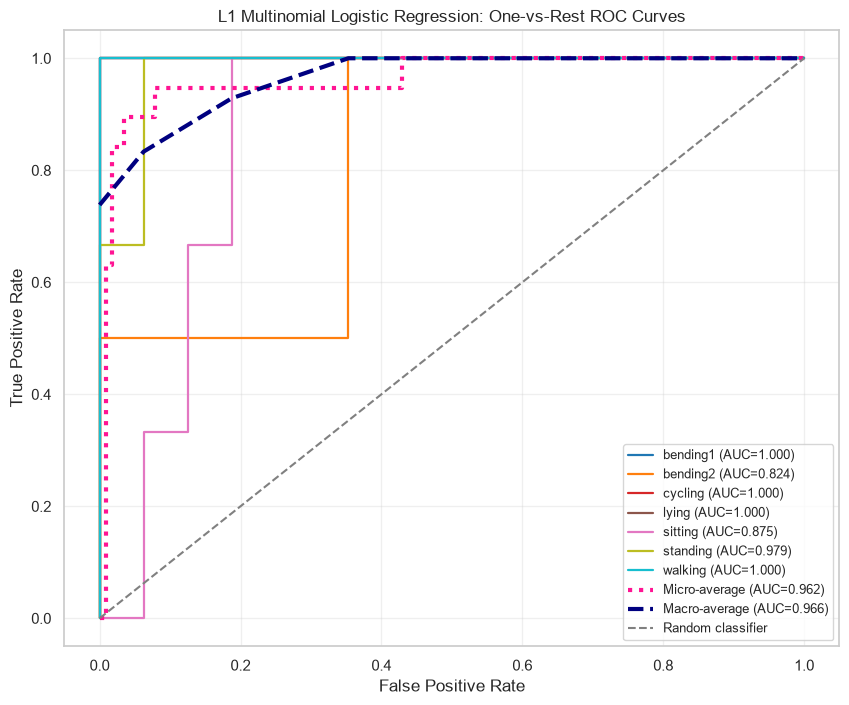

Micro-average AUC: 0.9621
Macro-average AUC: 0.9658


In [67]:
multiclass_auc_values = plot_multiclass_roc(
    y_multiclass_test,
    multiclass_test_probabilities,
    class_names,
    "L1 Multinomial Logistic Regression: One-vs-Rest ROC Curves"
)

print("Micro-average AUC:", round(multiclass_auc_values["micro"], 4))
print("Macro-average AUC:", round(multiclass_auc_values["macro"], 4))

Because `bending2` has only 4 training instances, 4-fold stratified CV was used so that every fold contains every activity. The best model uses $l = 2$ and $C \approx 4.64$ (CV accuracy 0.914). **Test error = 0.158** (3 of 19 misclassified); the errors involve sitting and bending2.

For multiclass problems, the confusion matrix is $7 \times 7$ (rows are true activities, columns are predicted). ROC curves are drawn one-vs-rest, treating each activity in turn as the positive class, and then averaged. Micro-averaging pools all decisions, while macro-averaging weights every activity equally. Here the micro-average AUC is 0.962 and the macro-average AUC is 0.966.

#### ii. Naive Bayes

In [68]:
gaussian_nb_pipeline = Pipeline([
    ("scale", StandardScaler()),
    (
        "classifier",
        GaussianNB()
    )
])

In [69]:
multinomial_nb_pipeline = Pipeline([
    (
        "scale",
        MinMaxScaler(clip=True)
    ),
    (
        "classifier",
        MultinomialNB(
            alpha=1.0,
            fit_prior=True
        )
    )
])

In [70]:
nb_search_results = []

for l in range(1, 21):
    X_l, activity_l, feature_names = prepare_segmented_data(
        train_instances,
        l
    )
    y_l = activity_l

    scoring_metrics = {
        "accuracy": "accuracy",
        "macro_auc": "roc_auc_ovr"
    }

    gaussian_scores = cross_validate(
        gaussian_nb_pipeline,
        X_l,
        y_l,
        cv=multiclass_cv,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    multinomial_scores = cross_validate(
        multinomial_nb_pipeline,
        X_l,
        y_l,
        cv=multiclass_cv,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    nb_search_results.append({
        "model": "GaussianNB",
        "l": l,
        "total_features": len(feature_names),
        "mean_cv_accuracy":
            gaussian_scores["test_accuracy"].mean(),
        "std_cv_accuracy":
            gaussian_scores["test_accuracy"].std(),
        "mean_cv_macro_auc":
            gaussian_scores["test_macro_auc"].mean(),
        "std_cv_macro_auc":
            gaussian_scores["test_macro_auc"].std()
    })

    nb_search_results.append({
        "model": "MultinomialNB",
        "l": l,
        "total_features": len(feature_names),
        "mean_cv_accuracy":
            multinomial_scores["test_accuracy"].mean(),
        "std_cv_accuracy":
            multinomial_scores["test_accuracy"].std(),
        "mean_cv_macro_auc":
            multinomial_scores["test_macro_auc"].mean(),
        "std_cv_macro_auc":
            multinomial_scores["test_macro_auc"].std()
    })

    print(
        f"l={l:2d} | "
        f"Gaussian accuracy="
        f"{gaussian_scores['test_accuracy'].mean():.4f} | "
        f"Multinomial accuracy="
        f"{multinomial_scores['test_accuracy'].mean():.4f}"
    )

l= 1 | Gaussian accuracy=0.8562 | Multinomial accuracy=0.7230
l= 2 | Gaussian accuracy=0.7966 | Multinomial accuracy=0.7672
l= 3 | Gaussian accuracy=0.6503 | Multinomial accuracy=0.6953
l= 4 | Gaussian accuracy=0.6650 | Multinomial accuracy=0.6944
l= 5 | Gaussian accuracy=0.5490 | Multinomial accuracy=0.7672
l= 6 | Gaussian accuracy=0.6511 | Multinomial accuracy=0.7516
l= 7 | Gaussian accuracy=0.6797 | Multinomial accuracy=0.7377
l= 8 | Gaussian accuracy=0.6936 | Multinomial accuracy=0.7239
l= 9 | Gaussian accuracy=0.5931 | Multinomial accuracy=0.7377
l=10 | Gaussian accuracy=0.6364 | Multinomial accuracy=0.7230
l=11 | Gaussian accuracy=0.6503 | Multinomial accuracy=0.6806
l=12 | Gaussian accuracy=0.5637 | Multinomial accuracy=0.6667
l=13 | Gaussian accuracy=0.5956 | Multinomial accuracy=0.6953
l=14 | Gaussian accuracy=0.5515 | Multinomial accuracy=0.7092
l=15 | Gaussian accuracy=0.5212 | Multinomial accuracy=0.6814
l=16 | Gaussian accuracy=0.5507 | Multinomial accuracy=0.6961
l=17 | G

In [71]:
nb_results_df = pd.DataFrame(
    nb_search_results
)

gaussian_results = (
    nb_results_df[
        nb_results_df["model"] == "GaussianNB"
    ]
    .sort_values(
        by=["mean_cv_accuracy", "l"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

multinomial_results = (
    nb_results_df[
        nb_results_df["model"] == "MultinomialNB"
    ]
    .sort_values(
        by=["mean_cv_accuracy", "l"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

best_gaussian_result = gaussian_results.iloc[0]
best_multinomial_result = multinomial_results.iloc[0]

best_gaussian_l = int(
    best_gaussian_result["l"]
)

best_multinomial_l = int(
    best_multinomial_result["l"]
)

print("Best GaussianNB l:", best_gaussian_l)
print(
    "GaussianNB CV accuracy:",
    round(
        best_gaussian_result[
            "mean_cv_accuracy"
        ],
        4
    )
)

print("\nBest MultinomialNB l:", best_multinomial_l)
print(
    "MultinomialNB CV accuracy:",
    round(
        best_multinomial_result[
            "mean_cv_accuracy"
        ],
        4
    )
)

Best GaussianNB l: 1
GaussianNB CV accuracy: 0.8562

Best MultinomialNB l: 2
MultinomialNB CV accuracy: 0.7672


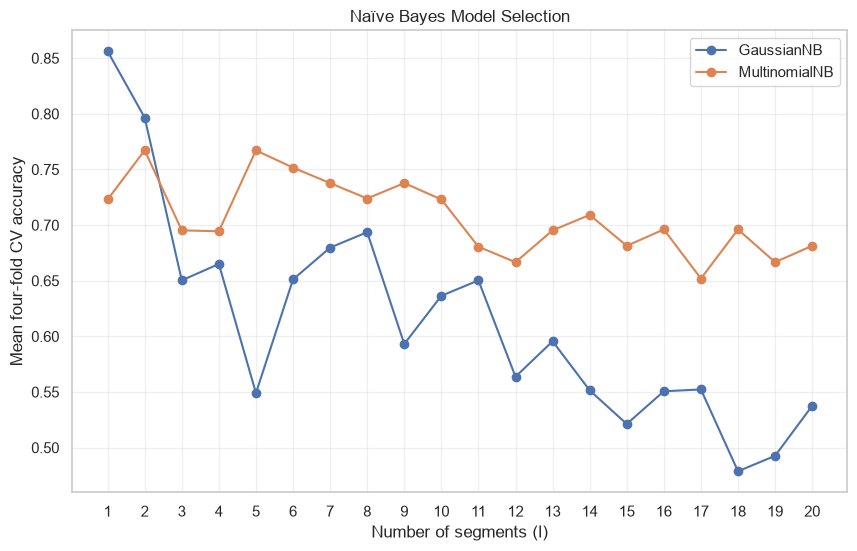

In [72]:
plt.figure(figsize=(10, 6))

for model_name, model_results in (
    nb_results_df.groupby("model")
):
    plt.plot(
        model_results["l"],
        model_results["mean_cv_accuracy"],
        marker="o",
        label=model_name
    )

plt.xticks(range(1, 21))
plt.xlabel("Number of segments (l)")
plt.ylabel("Mean four-fold CV accuracy")
plt.title("Naïve Bayes Model Selection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [73]:
(
    X_gaussian_train,
    y_gaussian_train,
    gaussian_feature_names
) = prepare_segmented_data(
    train_instances,
    best_gaussian_l
)

(
    X_gaussian_test,
    y_gaussian_test,
    _
) = prepare_segmented_data(
    test_instances,
    best_gaussian_l
)

gaussian_final_model = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", GaussianNB())
])

gaussian_final_model.fit(
    X_gaussian_train,
    y_gaussian_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U8](7,)","['bending1','bending2','cycling',...,'sitting','standing','walking']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](42,)","['min1_part1','max1_part1','mean1_part1',...,'std6_part1', '1st_quart6_part1','3rd_quart6_part1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [74]:
(
    X_multinomial_train,
    y_multinomial_train,
    multinomial_feature_names
) = prepare_segmented_data(
    train_instances,
    best_multinomial_l
)

(
    X_multinomial_test,
    y_multinomial_test,
    _
) = prepare_segmented_data(
    test_instances,
    best_multinomial_l
)

multinomial_final_model = Pipeline([
    (
        "scale",
        MinMaxScaler(clip=True)
    ),
    (
        "classifier",
        MultinomialNB(
            alpha=1.0,
            fit_prior=True
        )
    )
])

multinomial_final_model.fit(
    X_multinomial_train,
    y_multinomial_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U8](7,)","['bending1','bending2','cycling',...,'sitting','standing','walking']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](84,)","['min1_part1','max1_part1','mean1_part1',...,'std6_part2', '1st_quart6_part2','3rd_quart6_part2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,84
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",True
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True


In [75]:
gaussian_test_predictions = (
    gaussian_final_model.predict(
        X_gaussian_test
    )
)

gaussian_test_probabilities = (
    gaussian_final_model.predict_proba(
        X_gaussian_test
    )
)

multinomial_test_predictions = (
    multinomial_final_model.predict(
        X_multinomial_test
    )
)

multinomial_test_probabilities = (
    multinomial_final_model.predict_proba(
        X_multinomial_test
    )
)

In [76]:
gaussian_test_accuracy = accuracy_score(
    y_gaussian_test,
    gaussian_test_predictions
)

multinomial_test_accuracy = accuracy_score(
    y_multinomial_test,
    multinomial_test_predictions
)

gaussian_test_error = (
    1 - gaussian_test_accuracy
)

multinomial_test_error = (
    1 - multinomial_test_accuracy
)

print(
    "GaussianNB test accuracy:",
    round(gaussian_test_accuracy, 4)
)

print(
    "GaussianNB test error:",
    round(gaussian_test_error, 4)
)

print(
    "\nMultinomialNB test accuracy:",
    round(multinomial_test_accuracy, 4)
)

print(
    "MultinomialNB test error:",
    round(multinomial_test_error, 4)
)

GaussianNB test accuracy: 0.8947
GaussianNB test error: 0.1053

MultinomialNB test accuracy: 0.7895
MultinomialNB test error: 0.2105


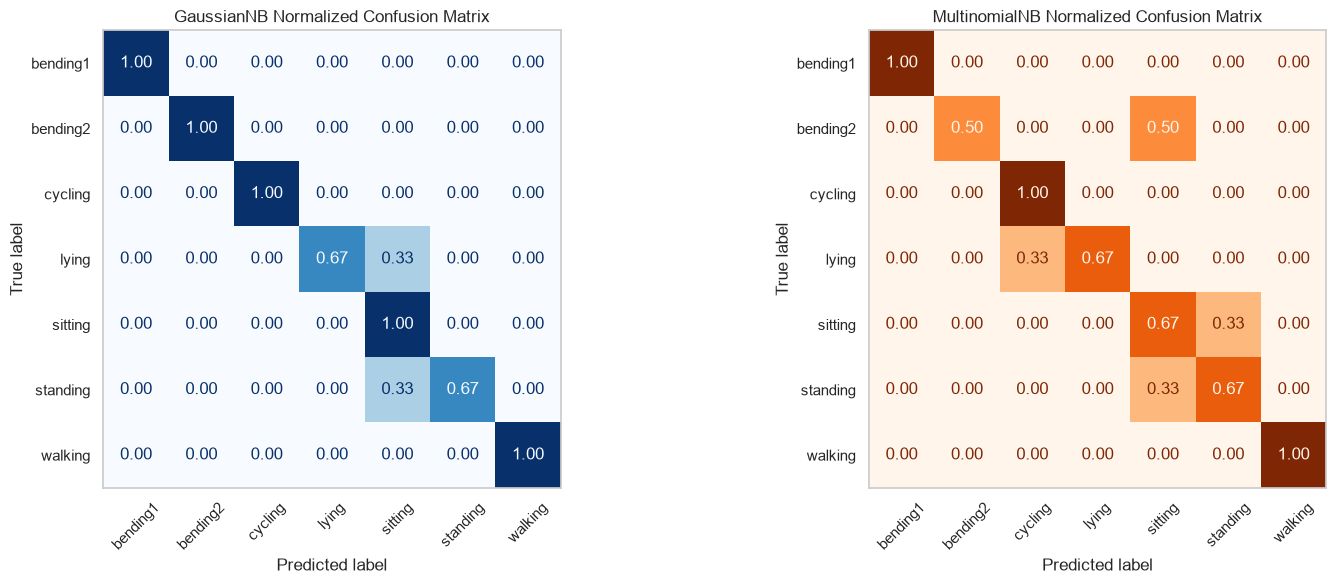

In [77]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

ConfusionMatrixDisplay.from_predictions(
    y_gaussian_test,
    gaussian_test_predictions,
    labels=class_names,
    display_labels=class_names,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title(
    "GaussianNB Normalized Confusion Matrix"
)
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_multinomial_test,
    multinomial_test_predictions,
    labels=class_names,
    display_labels=class_names,
    normalize="true",
    cmap="Oranges",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=False,
    ax=axes[1]
)

axes[1].set_title(
    "MultinomialNB Normalized Confusion Matrix"
)
axes[1].grid(False)

plt.tight_layout()
plt.show()

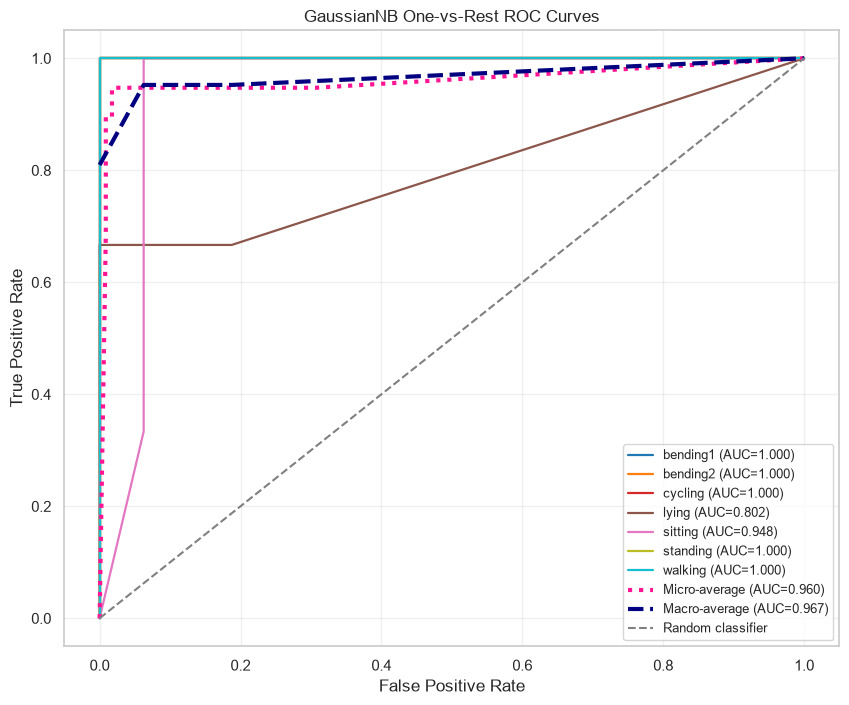

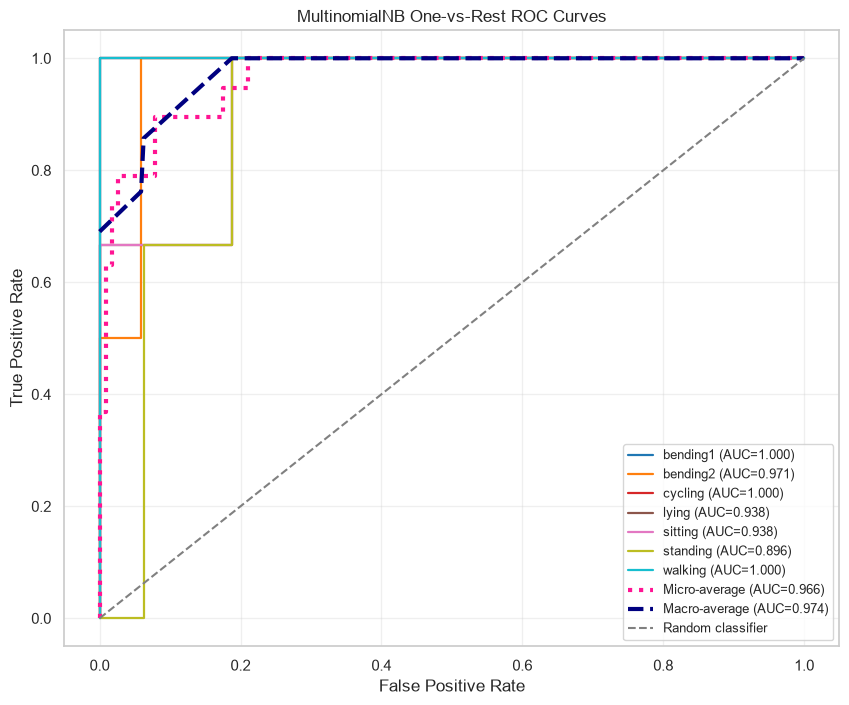

In [78]:
gaussian_auc_values = plot_multiclass_roc(
    y_gaussian_test,
    gaussian_test_probabilities,
    class_names,
    "GaussianNB One-vs-Rest ROC Curves"
)

multinomial_auc_values = plot_multiclass_roc(
    y_multinomial_test,
    multinomial_test_probabilities,
    class_names,
    "MultinomialNB One-vs-Rest ROC Curves"
)

In [79]:
nb_comparison = pd.DataFrame({
    "model": [
        "GaussianNB",
        "MultinomialNB"
    ],
    "best_l": [
        best_gaussian_l,
        best_multinomial_l
    ],
    "cv_accuracy": [
        best_gaussian_result[
            "mean_cv_accuracy"
        ],
        best_multinomial_result[
            "mean_cv_accuracy"
        ]
    ],
    "test_accuracy": [
        gaussian_test_accuracy,
        multinomial_test_accuracy
    ],
    "test_error": [
        gaussian_test_error,
        multinomial_test_error
    ],
    "test_macro_auc": [
        gaussian_auc_values["macro"],
        multinomial_auc_values["macro"]
    ],
    "test_micro_auc": [
        gaussian_auc_values["micro"],
        multinomial_auc_values["micro"]
    ]
})

nb_comparison.round(4)

,model,best_l,cv_accuracy,test_accuracy,test_error,test_macro_auc,test_micro_auc
0,GaussianNB,1,0.8562,0.8947,0.1053,0.9673,0.9598
1,MultinomialNB,2,0.7672,0.7895,0.2105,0.9743,0.9658


Gaussian NB (standardized features) selects $l = 1$ and has a test error of 0.105. Multinomial NB (min-max scaled features, since it requires nonnegative inputs) selects $l = 2$ and has a test error of 0.211. Multinomial NB has a slightly higher macro AUC (0.974 vs. 0.967), but Gaussian NB makes half as many errors (2 vs. 4), and its normality assumption suits continuous summary features better than the count-based multinomial model. Gaussian NB is the better of the two.

#### iii. Comparison

In [80]:
multiclass_method_comparison = pd.DataFrame({
    "model": [
        "L1 Multinomial Logistic Regression",
        "GaussianNB",
        "MultinomialNB"
    ],
    "best_l": [
        multiclass_best_l,
        best_gaussian_l,
        best_multinomial_l
    ],
    "cv_accuracy": [
        multiclass_best_cv_accuracy,
        best_gaussian_result["mean_cv_accuracy"],
        best_multinomial_result["mean_cv_accuracy"]
    ],
    "test_accuracy": [
        multiclass_test_accuracy,
        gaussian_test_accuracy,
        multinomial_test_accuracy
    ],
    "test_error": [
        multiclass_test_error,
        gaussian_test_error,
        multinomial_test_error
    ],
    "test_macro_auc": [
        multiclass_auc_values["macro"],
        gaussian_auc_values["macro"],
        multinomial_auc_values["macro"]
    ]
})

multiclass_method_comparison = (
    multiclass_method_comparison
    .sort_values(
        by=["test_error", "test_macro_auc"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

multiclass_method_comparison.round(4)

,model,best_l,cv_accuracy,test_accuracy,test_error,test_macro_auc
0,GaussianNB,1,0.8562,0.8947,0.1053,0.9673
1,L1 Multinomial Logistic Regression,2,0.9142,0.8421,0.1579,0.9658
2,MultinomialNB,2,0.7672,0.7895,0.2105,0.9743


Gaussian NB has the lowest test error (0.105, 2 of 19), ahead of L1 multinomial regression (0.158, 3 of 19) and Multinomial NB (0.211, 4 of 19), so by test error Gaussian NB performs best on this dataset. Its margin over L1 regression is a single test instance, though, and with 19 test instances one prediction changes the test error by about 5.3 percentage points.

From a modeling perspective, L1-penalized multinomial regression is arguably the more appropriate method: the features are continuous and highly correlated, and the L1 penalty removes unhelpful ones. Gaussian NB assumes the features are conditionally independent, which is unlikely for related statistics such as the mean, median, and quartiles, and Multinomial NB is designed for nonnegative count data.

## 3. ISLR 4.8.3

With one predictor and a class-specific variance, the density in class $k$ is

$$f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)$$

The Bayes classifier assigns $x$ to the class with the largest posterior probability,

$$P(Y=k\mid X=x) = \frac{\pi_k f_k(x)}{\sum_l \pi_l f_l(x)}$$

The denominator is the same for every class, so this is equivalent to maximizing $\log(\pi_k f_k(x))$. Dropping the constant $-\frac{1}{2}\log(2\pi)$, the discriminant function is

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}x - \frac{\mu_k^2}{2\sigma_k^2} + \log \pi_k - \log \sigma_k$$

In LDA, all classes share the same variance, $\sigma_k=\sigma$. Therefore, the term $-x^2/(2\sigma^2)$ is identical for every class and cancels when classes are compared, leaving a linear decision rule. Here, $\sigma_k$ differs between classes, so the coefficient of $x^2$, $-1/(2\sigma_k^2)$, also differs and does not cancel. Thus, each $\delta_k(x)$, and generally the boundary defined by $\delta_k(x)=\delta_l(x)$, is quadratic in $x$. The Bayes classifier is therefore quadratic rather than linear.

## 4. ISLR 4.8.7

Let $\pi_{\text{yes}} = 0.8$, $\pi_{\text{no}} = 0.2$, $\mu_{\text{yes}} = 10$, $\mu_{\text{no}} = 0$, and $\sigma^2 = 36$. By Bayes' theorem with normal densities (the common factor $1/\sqrt{2\pi\sigma^2}$ cancels):

$$P(\text{yes} \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.222}} = \frac{0.4852}{0.4852 + 0.1601} \approx 0.752.$$

The probability that the company issues a dividend this year is about **75.2%**.